# Banking_Transaction_Analysis - Phân Tích Dữ Liệu Giao Dịch Ngân Hàng
**Vai trò:** Chuyên viên phân tích dữ liệu ngân hàng  
**Dữ liệu:** 20.000 giao dịch (Banking_Transactional_Dataset.xlsx)  
**Công cụ:** Python (Pandas, Seaborn, Plotly, mlxtend)

## 📑 Mục lục
| Phần | Nội dung |
|---|---|
| **1** | Import thư viện & Load dữ liệu |
| **2** | Data Checking & Feature Engineering |
| **3** | EDA – Trả lời 4 nhóm câu hỏi của thử thách |
| 3.1 | Thông tin chuyên sâu & Phân khúc khách hàng |
| 3.2 | Phân tích hành vi giao dịch |
| 3.3 | Thông tin về Doanh thu & Chi phí |
| 3.4 | Phân tích Xu hướng & Hiệu suất |
| **4** | Conclusion & Khuyến nghị |

## 🧭 Bản đồ ghép phương pháp ↔ câu hỏi
| Câu hỏi | Phương pháp sử dụng |
|---|---|
| 1.1 Phân khúc giao dịch năng nổ nhất | Thống kê mô tả + **RFM** |
| 1.2 Sản phẩm phổ biến theo phân khúc | Thống kê mô tả (crosstab) + **Sankey** |
| 1.3 Điểm tín dụng vs tần suất / phí | Thống kê mô tả (tương quan Spearman) |
| 2.1 Loại giao dịch chiếm ưu thế | **Pareto 80/20** |
| 2.2 Thành phố/chi nhánh hot – kém hiệu quả | **ABC** + Pareto + bản đồ |
| 2.3 Thói quen Mobile / ATM / Branch / Online | Thống kê mô tả + kiểm định χ² + **Sankey** |
| 3.1 Nguồn doanh thu phí | **Pareto** |
| 3.2 Nhóm khách chịu chi phí không tương xứng | Burden Index + **RFM** |
| 3.3 Nguồn "ma sát" sinh doanh thu | **Funnel** (phí) + scatter tần suất–doanh thu |
| 4.1 Mùa vụ | Thống kê mô tả (chuỗi thời gian) |
| 4.2 Offer có phù hợp hành vi? | **Market Basket** + **Sankey** + **Funnel** (product holdings) |
| 4.3 Xu hướng mới nổi | **Cohort** + xu hướng kênh/phân khúc |

> ⚠️ **Cách dùng:** Upload file `Banking_Transactional_Dataset.xlsx` lên Google Drive, sửa biến `DRIVE_PATH` ở ô Load dữ liệu cho đúng đường dẫn, rồi chạy lần lượt từ trên xuống (Runtime ▸ Run all).

# 1️⃣ IMPORT THƯ VIỆN & LOAD DỮ LIỆU

In [ ]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from scipy import stats
from mlxtend.frequent_patterns import apriori, association_rules

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

import warnings

# Bỏ qua tất cả các cảnh báo thuộc loại DeprecationWarning
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Tải các bảng dữ liệu
FILE_PATH = '/content/drive/MyDrive/K04 - Scripts các buổi học/Dataset/Final Project/Banking_Transactional_Dataset.xlsx'

# Sheet 1: dữ liệu giao dịch | Sheet 2: mô tả các trường dữ liệu
df_raw  = pd.read_excel(FILE_PATH, sheet_name='Banking Data')
dict_df = pd.read_excel(FILE_PATH, sheet_name='Data Dictionary')

print('Kích thước dữ liệu:', df_raw.shape)
df_raw.head()

Kích thước dữ liệu: (20000, 19)


,TransactionID,CustomerID,TransactionDate,TransactionType,Amount,ProductCategory,ProductSubcategory,BranchCity,BranchLat,BranchLong,Channel,Currency,CreditCardFees,InsuranceFees,LatePaymentAmount,CustomerScore,MonthlyIncome,CustomerSegment,RecommendedOffer
0,1,8270,2025-01-29,Card Payment,6980.185223,Checking Account,Gold,Seville,37.3891,-5.9845,Branch,EUR,0.0,0.00,0.0,839,5767.68,Middle Income Segment,Mid-tier Savings Booster
1,2,1860,2023-02-10,Deposit,10786.371854,Mortgage,Gold,Murcia,37.9847,-1.1287,Branch,EUR,0.0,0.00,0.0,683,2441.00,Low Income Segment,Financial Literacy Program Access
2,3,6390,2024-03-07,Transfer,3982.761111,Loan,Platinum,Malaga,36.7213,-4.4214,ATM,EUR,0.0,92.46,0.0,500,9957.08,High Income Segment,Premium Investment Services
3,4,6191,2023-07-04,Withdrawal,12408.644136,Mortgage,Standard,Seville,37.3891,-5.9845,ATM,EUR,0.0,0.00,0.0,392,1545.80,Low Income Segment,Financial Literacy Program Access
4,5,6734,2025-02-05,Fee,1868.260998,Checking Account,Platinum,Murcia,37.9847,-1.1287,Mobile,USD,0.0,0.00,0.0,368,5825.27,Middle Income Segment,Mid-tier Savings Booster


# 2️⃣ DATA CHECKING & FEATURE ENGINEERING

## 2.1 Kiểm tra cấu trúc, giá trị thiếu, trùng lặp

In [ ]:
df_raw.info()
print('\n--- Giá trị thiếu ---')
print(df_raw.isna().sum()[lambda s: s > 0] if df_raw.isna().any().any() else 'Không có giá trị thiếu ✅')
print('\n--- Trùng lặp ---')
print('Số TransactionID trùng:', df_raw['TransactionID'].duplicated().sum())
print('Số dòng trùng hoàn toàn:', df_raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   TransactionID       20000 non-null  int64         
 1   CustomerID          20000 non-null  int64         
 2   TransactionDate     20000 non-null  datetime64[ns]
 3   TransactionType     20000 non-null  object        
 4   Amount              20000 non-null  float64       
 5   ProductCategory     20000 non-null  object        
 6   ProductSubcategory  20000 non-null  object        
 7   BranchCity          20000 non-null  object        
 8   BranchLat           20000 non-null  float64       
 9   BranchLong          20000 non-null  float64       
 10  Channel             20000 non-null  object        
 11  Currency            20000 non-null  object        
 12  CreditCardFees      20000 non-null  float64       
 13  InsuranceFees       20000 non-null  float64   

In [ ]:
# Thống kê mô tả các cột số
df_raw[['Amount','CreditCardFees','InsuranceFees','LatePaymentAmount','CustomerScore','MonthlyIncome']].describe().T

,count,mean,std,min,25%,50%,75%,max
Amount,20000.0,5050.355118,3526.028326,8.275197,2209.771959,4382.682068,7350.925301,14895.170734
CreditCardFees,20000.0,5.219896,12.221252,0.000000,0.000000,0.000000,0.000000,49.990000
InsuranceFees,20000.0,9.983711,23.716191,0.000000,0.000000,0.000000,0.000000,99.950000
LatePaymentAmount,20000.0,16.654402,44.109067,0.000000,0.000000,0.000000,0.000000,199.980000
CustomerScore,20000.0,575.297450,159.418177,300.000000,437.000000,577.000000,715.000000,849.000000
MonthlyIncome,20000.0,5484.947090,2601.897479,1000.860000,3224.785000,5473.545000,7736.802500,9998.880000


In [ ]:
# Phân bố các cột phân loại
for c in ['TransactionType','ProductCategory','ProductSubcategory','BranchCity','Channel','Currency','CustomerSegment','RecommendedOffer']:
    print(f'--- {c} ({df_raw[c].nunique()} giá trị) ---')
    print(df_raw[c].value_counts().to_string(), '\n')

--- TransactionType (6 giá trị) ---
TransactionType
Withdrawal      3395
Loan Payment    3369
Card Payment    3345
Fee             3308
Transfer        3293
Deposit         3290 

--- ProductCategory (5 giá trị) ---
ProductCategory
Credit Card         4082
Savings Account     4042
Loan                3998
Mortgage            3990
Checking Account    3888 

--- ProductSubcategory (5 giá trị) ---
ProductSubcategory
Student     4098
Business    4072
Platinum    3965
Gold        3956
Standard    3909 

--- BranchCity (8 giá trị) ---
BranchCity
Murcia       2564
Barcelona    2564
Malaga       2524
Seville      2513
Zaragoza     2476
Madrid       2472
Bilbao       2455
Valencia     2432 

--- Channel (4 giá trị) ---
Channel
Mobile    5219
Branch    5033
ATM       4883
Online    4865 

--- Currency (2 giá trị) ---
Currency
EUR    16974
USD     3026 

--- CustomerSegment (3 giá trị) ---
CustomerSegment
Middle Income Segment    8885
High Income Segment      6626
Low Income Segment       4489 



## 2.1 Kiểm tra cấu trúc, giá trị thiếu, trùng lặp

In [ ]:
print('Khoảng thời gian:', df_raw.TransactionDate.min().date(), '→', df_raw.TransactionDate.max().date())
print('Số khách hàng (CustomerID):', df_raw.CustomerID.nunique())
print('Amount <= 0:', (df_raw.Amount <= 0).sum(), '| Fee < 0:', (df_raw[['CreditCardFees','InsuranceFees','LatePaymentAmount']] < 0).sum().sum())

# (1) Một CustomerID có luôn giữ nguyên Segment / Income / Score giữa các giao dịch không?
chk = df_raw.groupby('CustomerID').agg(n_txn=('TransactionID','count'),
                                        n_segment=('CustomerSegment','nunique'),
                                        n_income=('MonthlyIncome','nunique'),
                                        n_score=('CustomerScore','nunique'))
multi = chk[chk.n_txn > 1]
print(f"\n(1) Trong {len(multi):,} khách có >=2 giao dịch:")
print(f"    - {(multi.n_segment>1).mean():.1%} khách có >1 CustomerSegment khác nhau")
print(f"    - {(multi.n_income>1).mean():.1%} khách có >1 mức MonthlyIncome khác nhau")
print(f"    - {(multi.n_score>1).mean():.1%} khách có >1 CustomerScore khác nhau")

# (2) Phí phát sinh ở loại giao dịch nào?
fee_cols = ['CreditCardFees','InsuranceFees','LatePaymentAmount']
print('\n(2) Tổng từng loại phí theo TransactionType:')
print(df_raw.groupby('TransactionType')[fee_cols].sum())
print('\n    ...và theo ProductCategory:')
print(df_raw.groupby('ProductCategory')[fee_cols].sum())

# (3) Hai đơn vị tiền tệ
print('\n(3) Amount trung bình theo Currency:')
print(df_raw.groupby('Currency').Amount.agg(['count','mean','median']))

# (4) Tháng cuối có đủ dữ liệu không?
print('\n(4) Số giao dịch 3 tháng cuối:')
print(df_raw.groupby(df_raw.TransactionDate.dt.to_period('M')).size().tail(3))

Khoảng thời gian: 2023-01-01 → 2025-05-20
Số khách hàng (CustomerID): 8025
Amount <= 0: 0 | Fee < 0: 0

(1) Trong 5,848 khách có >=2 giao dịch:
    - 79.8% khách có >1 CustomerSegment khác nhau
    - 100.0% khách có >1 mức MonthlyIncome khác nhau
    - 99.9% khách có >1 CustomerScore khác nhau

(2) Tổng từng loại phí theo TransactionType:
                 CreditCardFees  InsuranceFees  LatePaymentAmount
TransactionType                                                  
Card Payment           16993.46       32577.85               0.00
Deposit                17003.91       30796.79               0.00
Fee                    17913.58       32481.65               0.00
Loan Payment           17850.56       32309.97          333088.05
Transfer               16374.84       34662.02               0.00
Withdrawal             18261.57       36845.94               0.00

    ...và theo ProductCategory:
                  CreditCardFees  InsuranceFees  LatePaymentAmount
ProductCategory                

> 📝 **Ghi chú dữ liệu (rất quan trọng khi diễn giải):**
> 1. `CustomerSegment`, `MonthlyIncome`, `CustomerScore` **thay đổi theo từng giao dịch** của cùng một `CustomerID` → coi chúng là thuộc tính **tại thời điểm giao dịch**, không phải thuộc tính cố định của khách.
> 2. Phí gắn chặt với cấu trúc sản phẩm: `LatePaymentAmount` chỉ phát sinh ở giao dịch **Loan Payment** (và gần như *mọi* Loan Payment đều có khoản này); `CreditCardFees` chỉ xuất hiện ở sản phẩm **Credit Card**; `InsuranceFees` chỉ xuất hiện ở sản phẩm **Loan**.
> 3. Có 2 đơn vị tiền tệ (EUR, USD) nhưng không có tỷ giá → mặc định **không quy đổi** (có thể bật ở ô cấu hình bên dưới).
> 4. Tháng **05/2025 chỉ có dữ liệu đến 20/05** → tháng không đầy đủ, sẽ loại khỏi phân tích mùa vụ/xu hướng.

## 2.3 Feature Engineering

In [ ]:
# ====== Cấu hình ======
NORMALIZE_CURRENCY = False   # True nếu muốn quy đổi USD -> EUR
USD_TO_EUR = 0.9            # tỷ giá giả định, chỉnh theo nhu cầu
LAST_FULL_MONTH = pd.Period('2025-04', 'M')   # tháng cuối cùng có dữ liệu đầy đủ

SEGMENT_ORDER = ['Low Income Segment', 'Middle Income Segment', 'High Income Segment']
FEE_COLS = ['CreditCardFees', 'InsuranceFees', 'LatePaymentAmount']

df = df_raw.copy()
if NORMALIZE_CURRENCY:
    money_cols = ['Amount', 'MonthlyIncome'] + FEE_COLS
    df.loc[df.Currency == 'USD', money_cols] *= USD_TO_EUR

# ----- Thời gian -----
df['Year']      = df.TransactionDate.dt.year
df['Month']     = df.TransactionDate.dt.month
df['YearMonth'] = df.TransactionDate.dt.to_period('M')
df['Quarter']   = df.TransactionDate.dt.to_period('Q').astype(str)
df['Season']    = df.Month.map({12:'Đông',1:'Đông',2:'Đông',3:'Xuân',4:'Xuân',5:'Xuân',
                                6:'Hè',7:'Hè',8:'Hè',9:'Thu',10:'Thu',11:'Thu'})

# ----- Phí & chi phí -----
df['TotalFees']   = df[FEE_COLS].sum(axis=1)               # tổng doanh thu phí của giao dịch
df['HasFee']      = df.TotalFees > 0
df['FeeRate']     = df.TotalFees / df.Amount                # phí / giá trị giao dịch
df['FeeToIncome'] = df.TotalFees / df.MonthlyIncome         # phí / thu nhập tháng

# ----- Nhóm điểm tín dụng (thang FICO) -----
df['ScoreBand'] = pd.cut(df.CustomerScore, bins=[299, 579, 669, 739, 799, 850],
                         labels=['Poor (300-579)', 'Fair (580-669)', 'Good (670-739)',
                                 'Very Good (740-799)', 'Excellent (800+)'])
SCORE_ORDER = list(df.ScoreBand.cat.categories)

print('Số cột sau Feature Engineering:', df.shape[1])
df[['TransactionDate','YearMonth','Season','Amount','TotalFees','FeeRate','FeeToIncome','CustomerScore','ScoreBand']].head()

Số cột sau Feature Engineering: 29


,TransactionDate,YearMonth,Season,Amount,TotalFees,FeeRate,FeeToIncome,CustomerScore,ScoreBand
0,2025-01-29,2025-01,Đông,6980.185223,0.00,0.000000,0.000000,839,Excellent (800+)
1,2023-02-10,2023-02,Đông,10786.371854,0.00,0.000000,0.000000,683,Good (670-739)
2,2024-03-07,2024-03,Xuân,3982.761111,92.46,0.023215,0.009286,500,Poor (300-579)
3,2023-07-04,2023-07,Hè,12408.644136,0.00,0.000000,0.000000,392,Poor (300-579)
4,2025-02-05,2025-02,Đông,1868.260998,0.00,0.000000,0.000000,368,Poor (300-579)


## 2.4 Hàm tiện ích dùng chung (Pareto, ABC, Sankey, Burden Index)

In [ ]:
# ---------- Pareto: cột + đường lũy kế ----------
def pareto_table(s):
    s = s.sort_values(ascending=False)
    t = pd.DataFrame({'Value': s, 'Share_%': s / s.sum() * 100})
    t['Cum_%'] = t['Share_%'].cumsum()
    return t

def pareto_chart(s, title, ax=None, color='#4C72B0'):
    t = pareto_table(s)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4.5))
    x = np.arange(len(t))
    ax.bar(x, t['Value'], color=color)
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=30, ha='right')
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(x, t['Cum_%'], color='#C44E52', marker='o')
    ax2.axhline(80, ls='--', color='grey', lw=1)
    ax2.set_ylim(0, 105); ax2.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax2.grid(False)
    return t

# ---------- ABC: A = nhóm tạo 70% giá trị đầu, B = 20% tiếp, C = 10% cuối ----------
def abc_classify(s, a=0.70, b=0.90):
    s = s.sort_values(ascending=False)
    cum_prev = s.cumsum().shift(fill_value=0) / s.sum()
    cls = np.where(cum_prev < a, 'A', np.where(cum_prev < b, 'B', 'C'))
    return pd.DataFrame({'Value': s, 'Share_%': s / s.sum() * 100,
                         'Cum_%': s.cumsum() / s.sum() * 100, 'ABC': cls})

# ---------- Sankey nhiều tầng ----------
def draw_sankey(data, cols, title, height=520):
    labels, idx = [], {}
    for c in cols:
        for v in sorted(data[c].astype(str).unique()):
            idx[(c, v)] = len(labels); labels.append(v)
    src, tgt, val = [], [], []
    for a, b in zip(cols[:-1], cols[1:]):
        flow = data.assign(_a=data[a].astype(str), _b=data[b].astype(str)).groupby(['_a', '_b']).size()
        for (va, vb), n in flow.items():
            src.append(idx[(a, va)]); tgt.append(idx[(b, vb)]); val.append(int(n))
    fig = go.Figure(go.Sankey(node=dict(label=labels, pad=18, thickness=18),
                              link=dict(source=src, target=tgt, value=val)))
    fig.update_layout(title_text=title, height=height, font_size=12)
    fig.show()

# ---------- Burden Index: tỷ trọng phí / tỷ trọng giá trị giao dịch ----------
def burden_index(col):
    g = df.groupby(col, observed=True).agg(Txn=('TransactionID', 'count'), Amount=('Amount', 'sum'),
                                           Fees=('TotalFees', 'sum'))
    g['Fee_per_Txn']      = g.Fees / g.Txn
    g['Fee_rate_%']       = g.Fees / g.Amount * 100
    g['Fee_to_Income_%']  = df.groupby(col, observed=True).FeeToIncome.mean() * 100
    g['Burden_Index']     = (g.Fees / g.Fees.sum()) / (g.Amount / g.Amount.sum())   # >1 = chịu phí vượt tỷ trọng
    return g

def heat(ct, title, fmt='.1f', cmap='Blues', figsize=(9, 4)):
    plt.figure(figsize=figsize)
    sns.heatmap(ct, annot=True, fmt=fmt, cmap=cmap, linewidths=.5)
    plt.title(title); plt.tight_layout(); plt.show()

# 3️⃣ EDA – TRẢ LỜI CÁC CÂU HỎI CỦA THỬ THÁCH

## 3.1 THÔNG TIN CHUYÊN SÂU & PHÂN KHÚC KHÁCH HÀNG

### 3.1.1 Phân khúc khách hàng nào giao dịch năng nổ nhất?
**Phương pháp:** Thống kê mô tả (theo phân khúc) → **RFM** (đi sâu theo từng khách hàng)

**Bước 1 – Thống kê mô tả theo phân khúc.** Vì quy mô các phân khúc khác nhau, cần so sánh cả *tổng* lẫn *bình quân trên mỗi khách hàng*.

In [ ]:
seg = df.groupby('CustomerSegment').agg(So_GD=('TransactionID', 'count'),
                                        So_KH=('CustomerID', 'nunique'),
                                        Tong_GiaTri=('Amount', 'sum'),
                                        GiaTri_TB=('Amount', 'mean'),
                                        Tong_Phi=('TotalFees', 'sum')).reindex(SEGMENT_ORDER)
seg['%_GD']          = seg.So_GD / seg.So_GD.sum() * 100
seg['GD_tren_KH']    = seg.So_GD / seg.So_KH
seg['GiaTri_tren_KH']= seg.Tong_GiaTri / seg.So_KH
seg

,So_GD,So_KH,Tong_GiaTri,GiaTri_TB,Tong_Phi,%_GD,GD_tren_KH,GiaTri_tren_KH
CustomerSegment,,,,,,,,
Low Income Segment,4489,3530,2.214873e+07,4934.001104,140383.67,22.445,1.271671,6274.428033
Middle Income Segment,8885,5680,4.551802e+07,5123.018213,286605.97,44.425,1.564261,8013.735356
High Income Segment,6626,4647,3.334035e+07,5031.746842,210170.55,33.130,1.425866,7174.597498


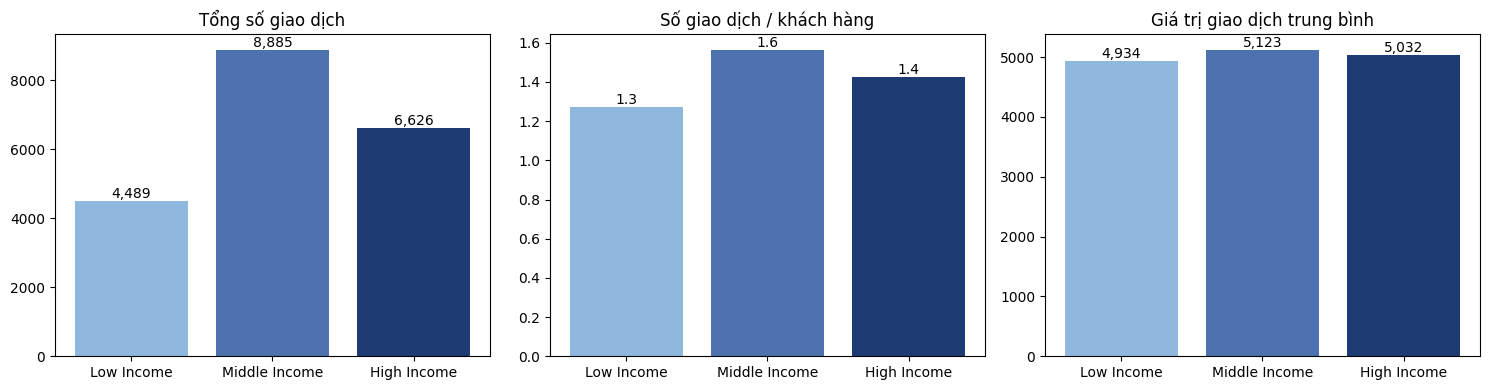

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
colors = ['#8FB8DE', '#4C72B0', '#1F3B73']
for a, col, ttl in zip(ax, ['So_GD', 'GD_tren_KH', 'GiaTri_TB'],
                       ['Tổng số giao dịch', 'Số giao dịch / khách hàng', 'Giá trị giao dịch trung bình']):
    a.bar([s.replace(' Segment', '') for s in seg.index], seg[col], color=colors)
    a.set_title(ttl)
    for i, v in enumerate(seg[col]): a.text(i, v, f'{v:,.1f}' if v < 100 else f'{v:,.0f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

**Bước 2 – RFM Segmentation (cấp khách hàng).**
- **Recency**: số ngày kể từ giao dịch gần nhất (càng nhỏ càng tốt) | **Frequency**: số giao dịch | **Monetary**: tổng giá trị giao dịch.
- Do đa số khách chỉ có 1–4 giao dịch, **Frequency** được chấm điểm theo ngưỡng cố định (1, 2, 3, 4, ≥5 giao dịch → 1–5 điểm) thay vì chia phân vị (phân vị sẽ bị trùng giá trị).

In [ ]:
snapshot = df.TransactionDate.max() + pd.Timedelta(days=1)

rfm = df.sort_values('TransactionDate').groupby('CustomerID').agg(
        Recency=('TransactionDate', lambda x: (snapshot - x.max()).days),
        Frequency=('TransactionID', 'count'),
        Monetary=('Amount', 'sum'),
        Fees=('TotalFees', 'sum'),
        FirstScore=('CustomerScore', 'first'),     # điểm tại GD đầu tiên (tránh điểm TB bị co về giữa khi khách có nhiều GD)
        LastSegment=('CustomerSegment', 'last'),        # phân khúc ở giao dịch gần nhất
        NumCategories=('ProductCategory', 'nunique'))

# ---- Chấm điểm 1-5 ----
rfm['R'] = pd.qcut(rfm.Recency.rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M'] = pd.qcut(rfm.Monetary.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['F'] = pd.cut(rfm.Frequency, bins=[0, 1, 2, 3, 4, np.inf], labels=[1, 2, 3, 4, 5]).astype(int)
rfm['FM'] = ((rfm.F + rfm.M) / 2).round()

# ---- Gán nhãn phân đoạn ----
conds = [
    (rfm.R >= 4) & (rfm.FM >= 4),
    (rfm.R == 3) & (rfm.FM >= 4),
    (rfm.R >= 4) & (rfm.F == 1),
    (rfm.R >= 4),
    (rfm.R == 3) & (rfm.FM == 3),
    (rfm.R == 3),
    (rfm.R <= 2) & (rfm.FM >= 3),
    (rfm.R <= 2)]
labels = ['Champions', 'Loyal Customers', 'New Customers', 'Potential Loyalists',
          'Need Attention', 'About to Sleep', 'At Risk', 'Hibernating / Lost']
rfm['RFM_Segment'] = np.select(conds, labels, default='Other')

rfm_sum = rfm.groupby('RFM_Segment').agg(So_KH=('Monetary', 'size'), Recency_TB=('Recency', 'mean'),
                                         Frequency_TB=('Frequency', 'mean'), Monetary_TB=('Monetary', 'mean'),
                                         Tong_GiaTri=('Monetary', 'sum'), Tong_Phi=('Fees', 'sum')).reindex(labels)
rfm_sum['%_KH']       = rfm_sum.So_KH / rfm_sum.So_KH.sum() * 100
rfm_sum['%_GiaTri']   = rfm_sum.Tong_GiaTri / rfm_sum.Tong_GiaTri.sum() * 100
rfm_sum

,So_KH,Recency_TB,Frequency_TB,Monetary_TB,Tong_GiaTri,Tong_Phi,%_KH,%_GiaTri
RFM_Segment,,,,,,,,
Champions,1569,77.838113,4.106437,22432.813609,3.519708e+07,212504.42,19.551402,34.846148
Loyal Customers,613,229.419250,3.761827,21132.963233,1.295451e+07,74302.19,7.638629,12.825342
New Customers,451,86.592018,1.000000,5038.491151,2.272360e+06,13812.36,5.619938,2.249703
Potential Loyalists,1190,81.335294,2.328571,9277.198424,1.103987e+07,80890.22,14.828660,10.929792
Need Attention,222,232.148649,2.563063,13230.633906,2.937201e+06,17328.24,2.766355,2.907915
About to Sleep,770,235.661039,1.681818,6623.721835,5.100266e+06,39730.96,9.595016,5.049413
At Risk,980,447.469388,3.110204,18483.631123,1.811396e+07,100537.64,12.211838,17.933351
Hibernating / Lost,2230,549.203587,1.397758,6005.318682,1.339186e+07,98054.16,27.788162,13.258336


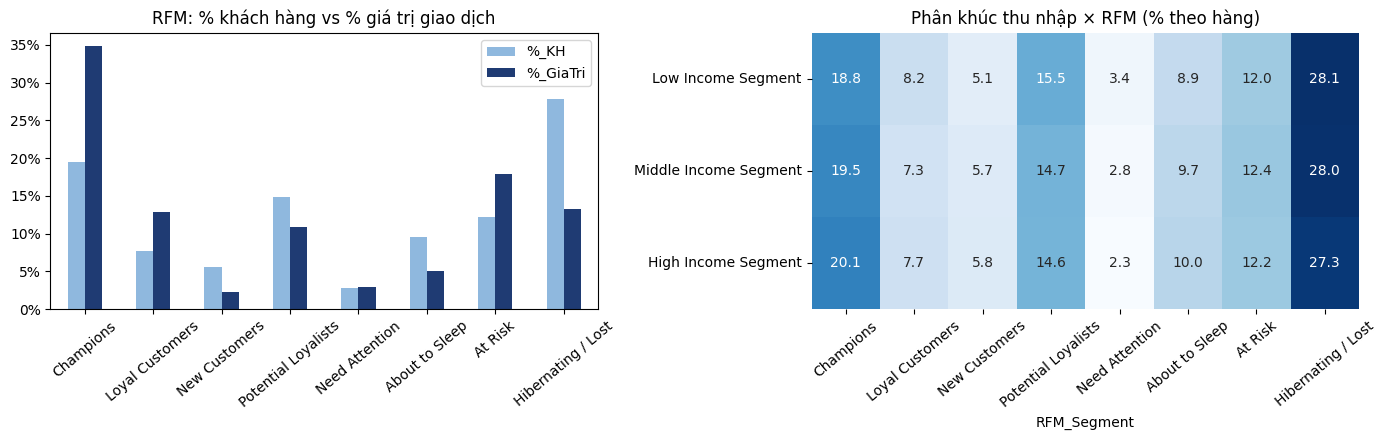

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
rfm_sum[['%_KH', '%_GiaTri']].plot(kind='bar', ax=ax[0], color=['#8FB8DE', '#1F3B73'])
ax[0].set_title('RFM: % khách hàng vs % giá trị giao dịch'); ax[0].set_xlabel(''); ax[0].yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax[0].tick_params(axis='x', rotation=40)

ct = pd.crosstab(rfm.LastSegment, rfm.RFM_Segment, normalize='index').reindex(SEGMENT_ORDER)[labels] * 100
sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues', ax=ax[1], cbar=False)
ax[1].set_title('Phân khúc thu nhập × RFM (% theo hàng)'); ax[1].set_ylabel(''); ax[1].tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.show()


> ### 💡 Nhận xét 1.1
> - **Phân khúc Middle Income năng nổ nhất** ở mọi thước đo: 8.885 giao dịch (44,4%), tổng giá trị 45,5 triệu và 1,56 giao dịch/khách (High: 1,43; Low: 1,27). Tuy nhiên chênh lệch **giá trị trung bình mỗi giao dịch** giữa 3 phân khúc rất nhỏ (~4.900–5.100) → khác biệt nằm ở *số lượng khách/giao dịch*, không phải ở "độ lớn" giao dịch.
> - **RFM:** nhóm **Champions** chỉ chiếm ~19,6% khách nhưng tạo ~34,9% giá trị giao dịch; trong khi **Hibernating/Lost** chiếm 27,8% khách nhưng chỉ ~13,3% giá trị.
> - ⚠️ Nhóm cần ưu tiên: **At Risk** (12,2% khách, ~17,9% giá trị, đã ~447 ngày không giao dịch, trước đó giao dịch nhiều và giá trị cao) → mục tiêu win-back có ROI cao nhất.
> - Lưu ý: một `CustomerID` xuất hiện ở nhiều phân khúc khác nhau (xem Data Checking) nên cột "GD/khách" theo phân khúc chỉ mang tính tham khảo.


### 3.1.2 Sản phẩm tài chính nào phổ biến nhất trong từng phân khúc?
**Phương pháp:** Thống kê mô tả (crosstab) + **Sankey** (Phân khúc → Nhóm sản phẩm → Hạng sản phẩm)

In [ ]:
ct_cat = pd.crosstab(df.CustomerSegment, df.ProductCategory).reindex(SEGMENT_ORDER)
ct_cat_pct = ct_cat.div(ct_cat.sum(axis=1), axis=0) * 100
print('Số giao dịch:'); display(ct_cat)
print('\nTỷ trọng (% theo phân khúc):'); display(ct_cat_pct)
print('\nSản phẩm phổ biến nhất trong từng phân khúc:')
print(ct_cat_pct.idxmax(axis=1).to_frame('ProductCategory').join(ct_cat_pct.max(axis=1).rename('Share_%')))

Số giao dịch:


ProductCategory,Checking Account,Credit Card,Loan,Mortgage,Savings Account
CustomerSegment,,,,,
Low Income Segment,907,897,865,871,949
Middle Income Segment,1688,1837,1828,1795,1737
High Income Segment,1293,1348,1305,1324,1356



Tỷ trọng (% theo phân khúc):


ProductCategory,Checking Account,Credit Card,Loan,Mortgage,Savings Account
CustomerSegment,,,,,
Low Income Segment,20.204945,19.982179,19.269325,19.402985,21.140566
Middle Income Segment,18.998312,20.675295,20.574001,20.202589,19.549803
High Income Segment,19.514036,20.344099,19.695140,19.981890,20.464835



Sản phẩm phổ biến nhất trong từng phân khúc:
                       ProductCategory    Share_%
CustomerSegment                                  
Low Income Segment     Savings Account  21.140566
Middle Income Segment      Credit Card  20.675295
High Income Segment    Savings Account  20.464835


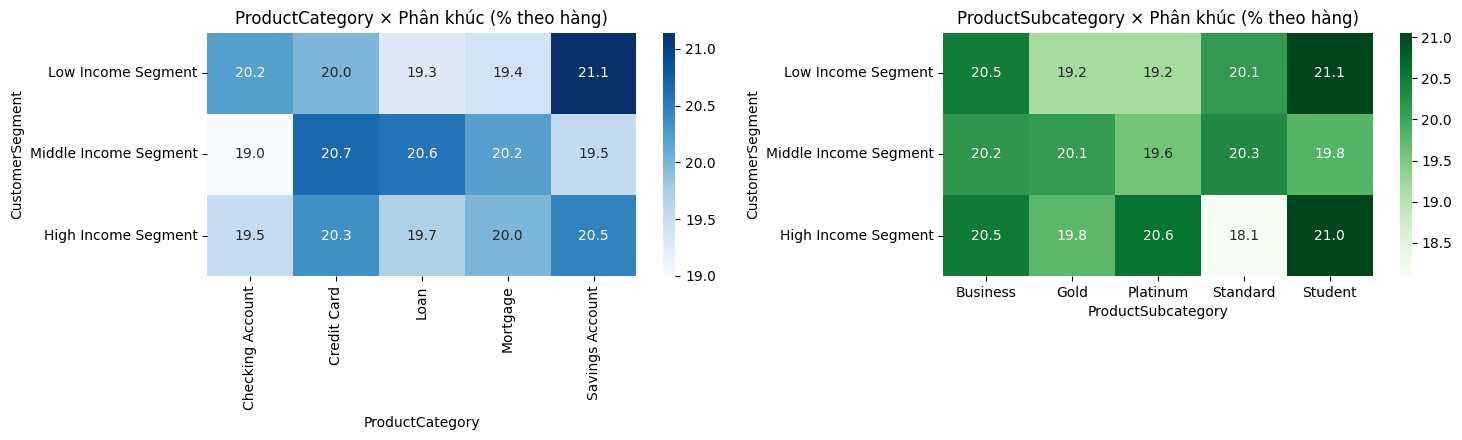

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(ct_cat_pct, annot=True, fmt='.1f', cmap='Blues', ax=ax[0]); ax[0].set_title('ProductCategory × Phân khúc (% theo hàng)')
ct_sub = pd.crosstab(df.CustomerSegment, df.ProductSubcategory, normalize='index').reindex(SEGMENT_ORDER) * 100
sns.heatmap(ct_sub, annot=True, fmt='.1f', cmap='Greens', ax=ax[1]); ax[1].set_title('ProductSubcategory × Phân khúc (% theo hàng)')
plt.tight_layout(); plt.show()

In [ ]:
# Kiểm định χ²: phân khúc có ảnh hưởng đến lựa chọn sản phẩm không?
chi2, p, dof, _ = stats.chi2_contingency(ct_cat)
print(f'χ² = {chi2:.2f}, dof = {dof}, p-value = {p:.4f} →', 'Có khác biệt ý nghĩa' if p < 0.05 else 'KHÔNG có khác biệt ý nghĩa thống kê (cơ cấu sản phẩm giống nhau giữa các phân khúc)')

χ² = 10.97, dof = 8, p-value = 0.2035 → KHÔNG có khác biệt ý nghĩa thống kê (cơ cấu sản phẩm giống nhau giữa các phân khúc)


In [ ]:
draw_sankey(df, ['CustomerSegment', 'ProductCategory', 'ProductSubcategory'], 'Sankey: Phân khúc → Nhóm sản phẩm → Hạng sản phẩm')


> ### 💡 Nhận xét 1.2
> - Mỗi phân khúc có cơ cấu sản phẩm **gần như đồng đều (~19–21% mỗi nhóm)**. Về hình thức: Low → *Savings Account* (21,1%), Middle → *Credit Card* (20,7%), High → *Savings Account* (20,5%).
> - Nhưng chênh lệch chưa tới 2 điểm % và kiểm định χ² cho **p ≈ 0,20 → không có khác biệt ý nghĩa thống kê**. Nghĩa là *"sản phẩm phổ biến nhất" trong từng phân khúc về thực chất là hòa* – không nên xây chiến lược sản phẩm riêng cho từng phân khúc chỉ dựa trên điểm này.
> - Sankey cho thấy dòng chảy Phân khúc → Sản phẩm → Hạng sản phẩm bị chia đều, không có "luồng chủ đạo" nào.


### 3.1.3 Điểm tín dụng có tỉ lệ thuận với tần suất giao dịch hoặc tổng phí tích lũy không?
**Phương pháp:** Thống kê mô tả + hệ số tương quan **Spearman** (phù hợp hơn Pearson vì dữ liệu không chuẩn, tần suất là số nguyên nhỏ)

Phân tích ở 2 cấp: **(a) Khách hàng** (điểm tín dụng tại giao dịch đầu tiên, số giao dịch, tổng phí tích lũy) và **(b) Giao dịch** (điểm vs phí mỗi giao dịch).

In [ ]:
# (a) Cấp khách hàng
rfm['ScoreBand'] = pd.cut(rfm.FirstScore, bins=[299, 579, 669, 739, 799, 850], labels=SCORE_ORDER)
band_c = rfm.groupby('ScoreBand', observed=True).agg(So_KH=('Frequency', 'size'),
                                                     GD_TB_moi_KH=('Frequency', 'mean'),
                                                     Phi_TB_moi_KH=('Fees', 'mean'),
                                                     GiaTri_TB_moi_KH=('Monetary', 'mean'))
display(band_c)

# (b) Cấp giao dịch
band_t = df.groupby('ScoreBand', observed=True).agg(So_GD=('TransactionID', 'count'),
                                                    Phi_TB_moi_GD=('TotalFees', 'mean'),
                                                    Ty_le_co_phi_pct=('HasFee', lambda x: x.mean() * 100))
display(band_t)

# Tương quan Spearman
rows = []
for name, x, y in [('KH: Điểm (GD đầu) ↔ Số giao dịch', rfm.FirstScore, rfm.Frequency),
                   ('KH: Điểm (GD đầu) ↔ Tổng phí',   rfm.FirstScore, rfm.Fees),
                   ('GD: CustomerScore ↔ Phí/GD',     df.CustomerScore, df.TotalFees),
                   ('GD: CustomerScore ↔ Amount',     df.CustomerScore, df.Amount)]:
    r, p = stats.spearmanr(x, y)
    rows.append({'Cặp biến': name, 'Spearman ρ': r, 'p-value': p,
                 'Kết luận': 'Có tương quan' if p < 0.05 else 'Không có tương quan'})
pd.DataFrame(rows)

,So_KH,GD_TB_moi_KH,Phi_TB_moi_KH,GiaTri_TB_moi_KH
ScoreBand,,,,
Poor (300-579),4075,2.504785,79.501372,12643.018661
Fair (580-669),1343,2.452718,78.473760,12575.054498
Good (670-739),1010,2.432673,77.640396,12229.412615
Very Good (740-799),856,2.514019,79.078096,12697.491135
Excellent (800+),741,2.550607,83.258016,12655.524915


,So_GD,Phi_TB_moi_GD,Ty_le_co_phi_pct
ScoreBand,,,
Poor (300-579),10139,31.177187,50.586843
Fair (580-669),3215,33.133760,50.824261
Good (670-739),2573,32.197738,50.524679
Very Good (740-799),2213,31.516941,49.796656
Excellent (800+),1860,33.299935,50.591398


,Cặp biến,Spearman ρ,p-value,Kết luận
0,KH: Điểm (GD đầu) ↔ Số giao dịch,0.001502,0.892986,Không có tương quan
1,KH: Điểm (GD đầu) ↔ Tổng phí,0.006533,0.558442,Không có tương quan
2,GD: CustomerScore ↔ Phí/GD,0.002959,0.675590,Không có tương quan
3,GD: CustomerScore ↔ Amount,-0.012600,0.074772,Không có tương quan


/tmp/ipykernel_1987/2139083197.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1987/2139083197.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




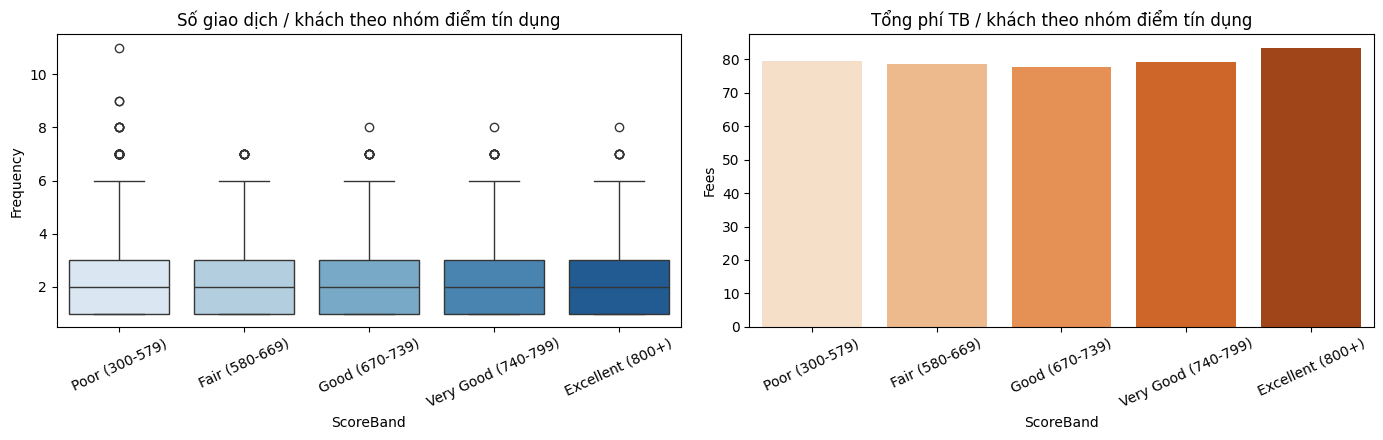

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=rfm, x='ScoreBand', y='Frequency', ax=ax[0], palette='Blues'); ax[0].set_title('Số giao dịch / khách theo nhóm điểm tín dụng'); ax[0].tick_params(axis='x', rotation=25)
sns.barplot(data=rfm, x='ScoreBand', y='Fees', ax=ax[1], palette='Oranges', errorbar=None); ax[1].set_title('Tổng phí TB / khách theo nhóm điểm tín dụng'); ax[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()


> ### 💡 Nhận xét 1.3
> - **Không.** Điểm tín dụng *không tỉ lệ thuận* với tần suất giao dịch hay tổng phí tích lũy: hệ số Spearman ρ ≈ 0 (p từ 0,56 đến 0,89) ở cả cấp khách hàng lẫn cấp giao dịch.
> - Mọi nhóm điểm (Poor → Excellent) đều có ~2,4–2,6 giao dịch/khách, ~78–83 phí tích lũy/khách và ~50% giao dịch phát sinh phí.
> - Hệ quả nghiệp vụ: **điểm tín dụng không phải là biến dự báo hữu ích** cho hành vi giao dịch/khả năng sinh phí trong bộ dữ liệu này; không nên dùng nó một mình để tinh chỉnh marketing hay định giá phí.
> - (Kỹ thuật: dùng điểm tại *giao dịch đầu tiên* của khách thay vì điểm trung bình để tránh hiện tượng điểm TB bị "co về giữa" ở khách có nhiều giao dịch.)


## 3.2 PHÂN TÍCH HÀNH VI GIAO DỊCH

### 3.2.1 Loại giao dịch nào chiếm ưu thế về số lượng và giá trị?
**Phương pháp:** **Pareto 80/20** – vẽ 2 biểu đồ (theo số lượng và theo giá trị) rồi so sánh.

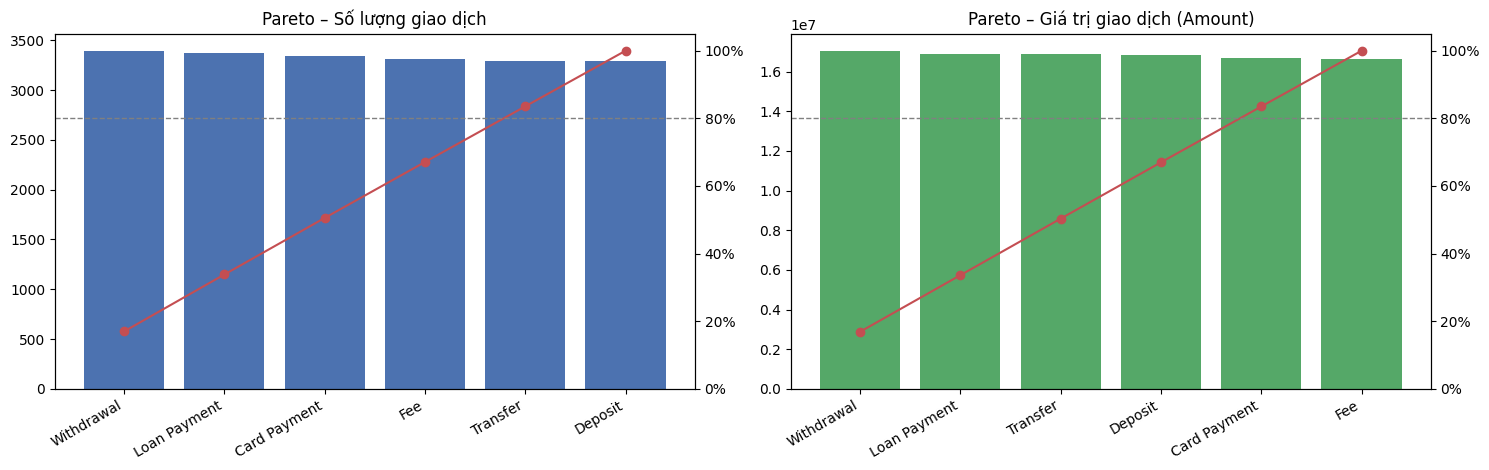

,So_GD,Tong_GiaTri,GiaTri_TB,GiaTri_Median,%_GD,%_GiaTri
TransactionType,,,,,,
Withdrawal,3395,1.705021e+07,5022.151861,4398.971480,16.975,16.880205
Loan Payment,3369,1.690050e+07,5016.474592,4347.296693,16.845,16.731995
Transfer,3293,1.689509e+07,5130.607718,4407.009236,16.465,16.726637
Deposit,3290,1.682519e+07,5114.038109,4438.794171,16.450,16.657428
Card Payment,3345,1.668064e+07,4986.739876,4302.400344,16.725,16.514329
Fee,3308,1.665547e+07,5034.907013,4439.511942,16.540,16.489407


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
t_cnt = pareto_chart(df.groupby('TransactionType').size(), 'Pareto – Số lượng giao dịch', ax[0], '#4C72B0')
t_amt = pareto_chart(df.groupby('TransactionType').Amount.sum(), 'Pareto – Giá trị giao dịch (Amount)', ax[1], '#55A868')
plt.tight_layout(); plt.show()

tt = pd.DataFrame({'So_GD': df.groupby('TransactionType').size(),
                   'Tong_GiaTri': df.groupby('TransactionType').Amount.sum(),
                   'GiaTri_TB': df.groupby('TransactionType').Amount.mean(),
                   'GiaTri_Median': df.groupby('TransactionType').Amount.median()})
tt['%_GD'] = tt.So_GD / tt.So_GD.sum() * 100
tt['%_GiaTri'] = tt.Tong_GiaTri / tt.Tong_GiaTri.sum() * 100
tt.sort_values('Tong_GiaTri', ascending=False)

In [ ]:
# Số loại giao dịch cần để đạt 80%
print('Số loại GD để đạt 80% SỐ LƯỢNG :', (t_cnt['Cum_%'] < 80).sum() + 1, '/', len(t_cnt))
print('Số loại GD để đạt 80% GIÁ TRỊ  :', (t_amt['Cum_%'] < 80).sum() + 1, '/', len(t_amt))
# Kiểm định: Amount có khác nhau giữa các loại GD không?
groups = [g.Amount.values for _, g in df.groupby('TransactionType')]
h, p = stats.kruskal(*groups)
print(f'Kruskal-Wallis: H = {h:.2f}, p = {p:.4f} →', 'Có khác biệt' if p < 0.05 else 'Giá trị GD không khác biệt đáng kể giữa các loại')

Số loại GD để đạt 80% SỐ LƯỢNG : 5 / 6
Số loại GD để đạt 80% GIÁ TRỊ  : 5 / 6
Kruskal-Wallis: H = 2.89, p = 0.7175 → Giá trị GD không khác biệt đáng kể giữa các loại



> ### 💡 Nhận xét 2.1
> - Không có loại giao dịch nào "thống trị". 6 loại giao dịch chia đều **16,5–17,0%** cả về số lượng lẫn giá trị. *Withdrawal* nhỉnh nhất ở cả hai thước đo (3.395 GD; ~17,05 triệu) nhưng chỉ hơn loại thấp nhất vài chục giao dịch.
> - **Quy luật 80/20 không xuất hiện:** cần tới **5/6 loại** mới đạt 80%. Kiểm định Kruskal-Wallis (p ≈ 0,72) xác nhận giá trị giao dịch không khác nhau giữa các loại.
> - Hàm ý: tối ưu vận hành theo "loại giao dịch" khó tạo đòn bẩy; **đòn bẩy nằm ở cấu trúc phí** (xem 3.1), không nằm ở khối lượng.


### 3.2.2 Thành phố / chi nhánh nào là "điểm nóng", nơi nào hoạt động kém hiệu quả?
**Phương pháp:** **ABC** (xếp hạng A/B/C) + Pareto + bản đồ. Dữ liệu chỉ có `BranchCity` nên ta phân tích ở 2 mức: **Thành phố** (8) và **Điểm phục vụ = Thành phố × Kênh** (32).

In [ ]:
city = df.groupby('BranchCity').agg(So_GD=('TransactionID', 'count'), So_KH=('CustomerID', 'nunique'),
                                    Tong_GiaTri=('Amount', 'sum'), GiaTri_TB=('Amount', 'mean'),
                                    Tong_Phi=('TotalFees', 'sum'), Lat=('BranchLat', 'mean'), Lon=('BranchLong', 'mean'))
city['Phi_tren_GD'] = city.Tong_Phi / city.So_GD
city['Ty_le_phi_%'] = city.Tong_Phi / city.Tong_GiaTri * 100
abc_city = abc_classify(city.Tong_GiaTri).rename(columns={'Value': 'Tong_GiaTri'})[['Share_%', 'Cum_%', 'ABC']]
city = city.join(abc_city).sort_values('Tong_GiaTri', ascending=False)
city.drop(columns=['Lat', 'Lon'])

,So_GD,So_KH,Tong_GiaTri,GiaTri_TB,Tong_Phi,Phi_tren_GD,Ty_le_phi_%,Share_%,Cum_%,ABC
BranchCity,,,,,,,,,,
Barcelona,2564,2230,1.303362e+07,5083.316904,85250.20,33.248908,0.654079,12.903671,12.903671,A
Malaga,2524,2193,1.291749e+07,5117.865591,85077.02,33.707219,0.658619,12.788697,25.692369,A
Murcia,2564,2218,1.289990e+07,5031.163324,85054.84,33.172715,0.659345,12.771283,38.463652,A
Seville,2513,2203,1.267313e+07,5043.027575,73957.22,29.429853,0.583575,12.546769,51.010421,A
Zaragoza,2476,2156,1.262357e+07,5098.373229,75619.97,30.541183,0.599038,12.497707,63.508129,A
Valencia,2432,2148,1.245838e+07,5122.690096,76135.04,31.305526,0.611115,12.334165,75.842293,A
Bilbao,2455,2122,1.221914e+07,4977.247229,75766.06,30.861939,0.620060,12.097310,87.939603,B
Madrid,2472,2147,1.218186e+07,4927.935929,80299.84,32.483754,0.659176,12.060397,100.000000,B


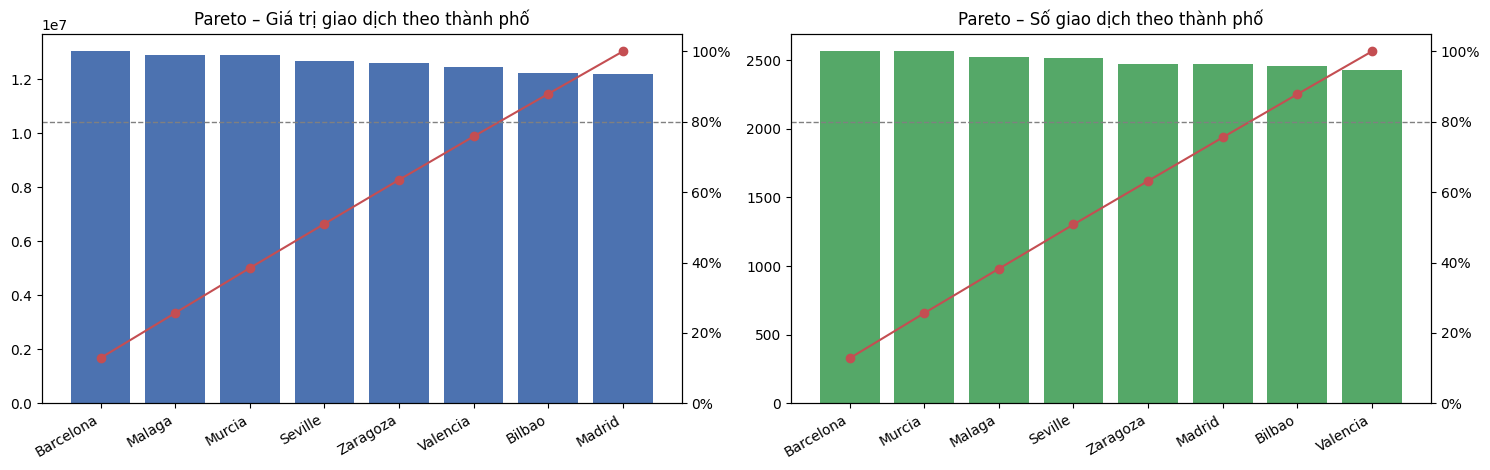

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
pareto_chart(city.Tong_GiaTri, 'Pareto – Giá trị giao dịch theo thành phố', ax[0])
pareto_chart(city.So_GD, 'Pareto – Số giao dịch theo thành phố', ax[1], '#55A868')
plt.tight_layout(); plt.show()

# Bản đồ: kích thước = giá trị GD, màu = số GD
fig = px.scatter_geo(city.reset_index(), lat='Lat', lon='Lon', size='Tong_GiaTri', color='So_GD', hover_name='BranchCity',
                     hover_data={'Tong_GiaTri': ':,.0f', 'So_GD': True, 'Lat': False, 'Lon': False},
                     color_continuous_scale='Blues', scope='europe', title='Bản đồ hiệu suất theo thành phố')
fig.update_geos(lataxis_range=[35, 44], lonaxis_range=[-10, 4], showcountries=True, showland=True)
fig.update_layout(height=500); fig.show()

ABC
A    22
B     7
C     3

Top 5 điểm phục vụ (A):


,Tong_GiaTri,Share_%,Cum_%,ABC,So_GD,Tong_Phi
Branch,,,,,,
Valencia | Mobile,3.529129e+06,3.493941,3.493941,A,673,21517.62
Barcelona | Online,3.420006e+06,3.385907,6.879848,A,645,22493.64
Murcia | ATM,3.416232e+06,3.382170,10.262018,A,644,22342.67
Barcelona | Branch,3.389605e+06,3.355809,13.617827,A,648,21798.73
Barcelona | Mobile,3.383220e+06,3.349487,16.967314,A,687,22250.17


Bottom 5 điểm phục vụ (C):


,Tong_GiaTri,Share_%,Cum_%,ABC,So_GD,Tong_Phi
Branch,,,,,,
Zaragoza | Online,2.939375e+06,2.910068,88.700973,B,588,19286.68
Bilbao | ATM,2.934871e+06,2.905609,91.606582,B,584,16195.95
Seville | Online,2.897076e+06,2.868190,94.474772,C,594,17404.34
Barcelona | ATM,2.840793e+06,2.812469,97.287240,C,584,18707.66
Madrid | Online,2.740080e+06,2.712760,100.000000,C,549,17328.94


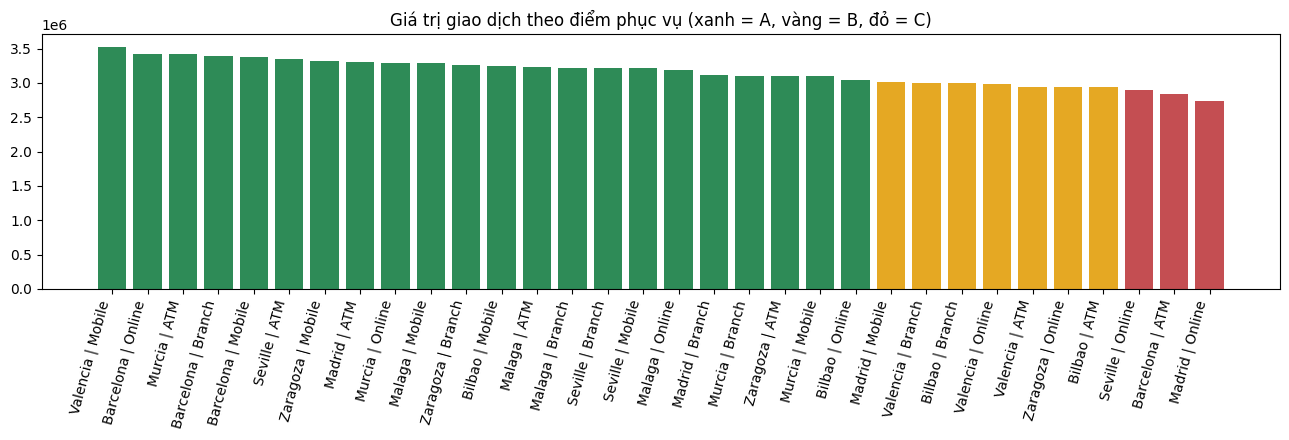

In [ ]:
# ABC cho 32 điểm phục vụ (Thành phố × Kênh)
pt = df.assign(Branch=df.BranchCity + ' | ' + df.Channel).groupby('Branch').agg(
        So_GD=('TransactionID', 'count'), Tong_GiaTri=('Amount', 'sum'), Tong_Phi=('TotalFees', 'sum'))
abc_pt = abc_classify(pt.Tong_GiaTri).rename(columns={'Value': 'Tong_GiaTri'}).join(pt[['So_GD', 'Tong_Phi']])
print(abc_pt.ABC.value_counts().sort_index().to_string())
print('\nTop 5 điểm phục vụ (A):'); display(abc_pt.head(5))
print('Bottom 5 điểm phục vụ (C):'); display(abc_pt.tail(5))

plt.figure(figsize=(13, 4.5))
cmap = {'A': '#2E8B57', 'B': '#E5A823', 'C': '#C44E52'}
plt.bar(abc_pt.index, abc_pt.Tong_GiaTri, color=abc_pt.ABC.map(cmap))
plt.xticks(rotation=75, ha='right'); plt.title('Giá trị giao dịch theo điểm phục vụ (xanh = A, vàng = B, đỏ = C)')
plt.tight_layout(); plt.show()

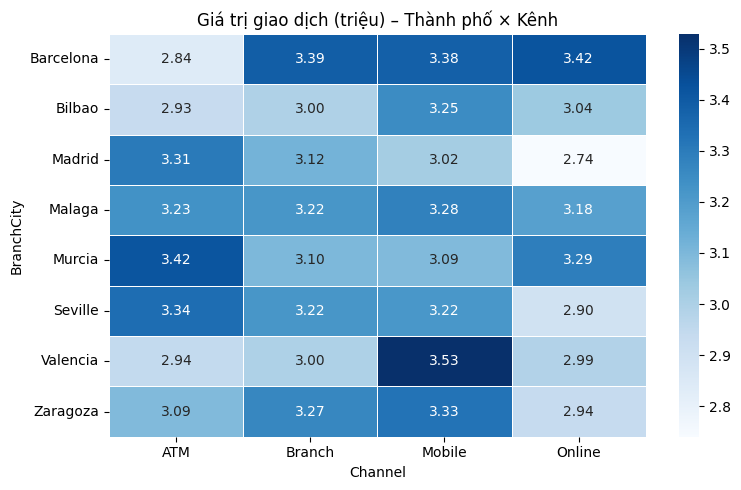

Chênh lệch giá trị GD: cao nhất = 7.0% so với thấp nhất


In [ ]:
# Ma trận Thành phố × Kênh (giá trị giao dịch, triệu)
heat(df.pivot_table(index='BranchCity', columns='Channel', values='Amount', aggfunc='sum') / 1e6,
     'Giá trị giao dịch (triệu) – Thành phố × Kênh', fmt='.2f', figsize=(8, 5))
# Chênh lệch giữa thành phố tốt nhất và kém nhất
print(f"Chênh lệch giá trị GD: cao nhất = {city.Tong_GiaTri.max()/city.Tong_GiaTri.min()-1:.1%} so với thấp nhất")


> ### 💡 Nhận xét 2.2
> - **Điểm nóng:** *Barcelona* (giá trị cao nhất ~13,03 triệu; 2.564 GD – đồng hạng với Murcia), *Malaga*, *Murcia*. Theo ABC: 6 thành phố đầu (Barcelona → Valencia) thuộc hạng **A**, *Bilbao* và *Madrid* thuộc hạng **B**, không có thành phố hạng C.
> - **Kém nhất:** *Madrid* (12,18 triệu, thấp hơn Barcelona 7%) – đáng chú ý vì là thủ đô nhưng thấp nhất cả về giá trị lẫn giá trị trung bình/GD (4.928).
> - Ở mức điểm phục vụ (Thành phố × Kênh): 22 điểm hạng A, 7 hạng B, 3 hạng C. Hạng **C** gồm *Seville | Online*, *Barcelona | ATM*, *Madrid | Online*; điểm tốt nhất là *Valencia | Mobile* (~3,53 triệu). Lưu ý *Madrid | Online* và *Barcelona | ATM* đáng soi kỹ vì Barcelona là thành phố mạnh nhất nhưng kênh ATM lại yếu.
> - Về doanh thu phí/GD: *Malaga* cao nhất (33,7), *Seville* thấp nhất (29,4).
> - ⚠️ Chênh lệch giữa các thành phố chỉ ~7% → "kém hiệu quả" ở đây là *tương đối*, không phải thất bại. Hành động nên là rà soát các điểm hạng C thay vì tái cấu trúc mạng lưới.


### 3.2.3 Sự khác biệt về thói quen sử dụng giữa Mobile, ATM, Branch (và Online)?
**Phương pháp:** Thống kê mô tả + kiểm định χ² + **Sankey** (Kênh → Loại giao dịch → Nhóm sản phẩm)

,So_GD,Tong_GiaTri,GiaTri_TB,GiaTri_Median,Phi_TB,Ty_le_co_phi,%_GD
Channel,,,,,,,
Mobile,5219,2.609981e+07,5000.920732,4349.436572,31.993050,51.255030,26.095
Branch,5033,2.530313e+07,5027.444354,4357.831483,32.343884,51.400755,25.165
ATM,4883,2.510550e+07,5141.407966,4518.433496,31.298997,49.436822,24.415
Online,4865,2.449867e+07,5035.698771,4322.068255,31.771570,49.948613,24.325


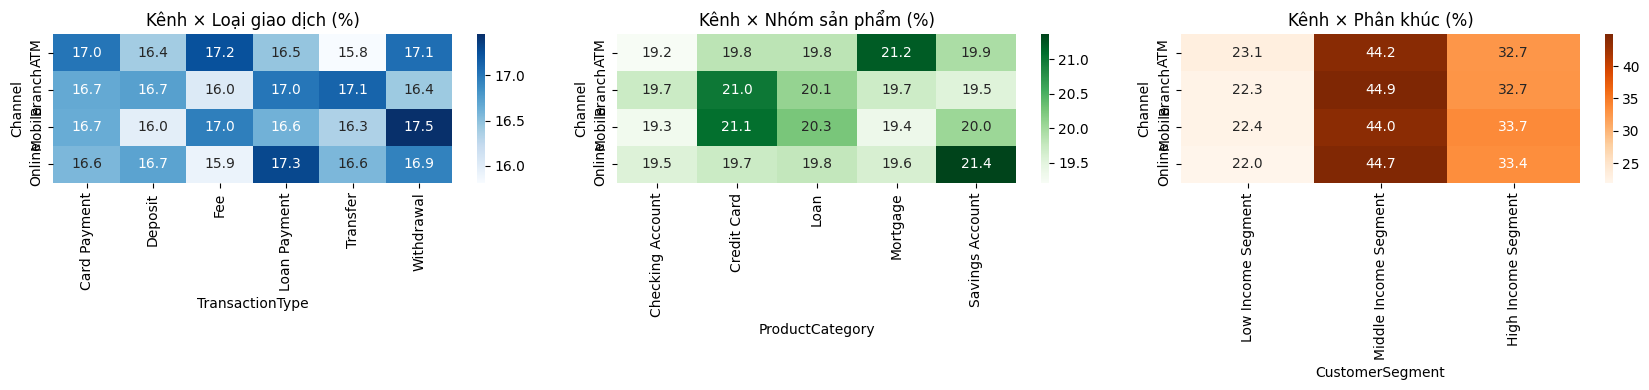

In [ ]:
ch = df.groupby('Channel').agg(So_GD=('TransactionID', 'count'), Tong_GiaTri=('Amount', 'sum'),
                               GiaTri_TB=('Amount', 'mean'), GiaTri_Median=('Amount', 'median'),
                               Phi_TB=('TotalFees', 'mean'), Ty_le_co_phi=('HasFee', 'mean'))
ch['%_GD'] = ch.So_GD / ch.So_GD.sum() * 100
ch['Ty_le_co_phi'] *= 100
display(ch.sort_values('So_GD', ascending=False))

ct_ch_type = pd.crosstab(df.Channel, df.TransactionType, normalize='index') * 100
ct_ch_cat  = pd.crosstab(df.Channel, df.ProductCategory,  normalize='index') * 100
ct_ch_seg  = pd.crosstab(df.Channel, df.CustomerSegment,  normalize='index')[SEGMENT_ORDER] * 100

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.heatmap(ct_ch_type, annot=True, fmt='.1f', cmap='Blues',   ax=ax[0]); ax[0].set_title('Kênh × Loại giao dịch (%)')
sns.heatmap(ct_ch_cat,  annot=True, fmt='.1f', cmap='Greens',  ax=ax[1]); ax[1].set_title('Kênh × Nhóm sản phẩm (%)')
sns.heatmap(ct_ch_seg,  annot=True, fmt='.1f', cmap='Oranges', ax=ax[2]); ax[2].set_title('Kênh × Phân khúc (%)')
plt.tight_layout(); plt.show()

Kênh vs TransactionType : χ² =  11.04, p = 0.7500 → không khác biệt
Kênh vs ProductCategory : χ² =  14.39, p = 0.2762 → không khác biệt
Kênh vs CustomerSegment : χ² =   3.33, p = 0.7667 → không khác biệt
Kênh vs Amount          : H =   4.80, p = 0.1868 → không khác biệt


/tmp/ipykernel_1987/1106396991.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




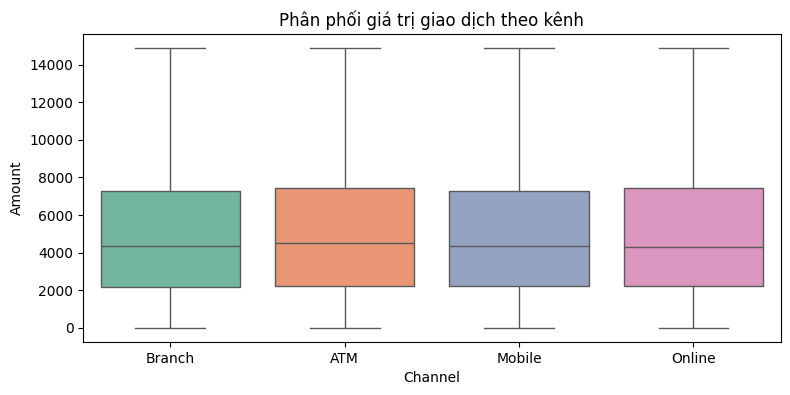

In [ ]:
# Kiểm định thống kê
for name, other in [('TransactionType', df.TransactionType), ('ProductCategory', df.ProductCategory), ('CustomerSegment', df.CustomerSegment)]:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df.Channel, other))
    print(f'Kênh vs {name:16s}: χ² = {chi2:6.2f}, p = {p:.4f} →', 'khác biệt' if p < 0.05 else 'không khác biệt')
h, p = stats.kruskal(*[g.Amount.values for _, g in df.groupby('Channel')])
print(f'Kênh vs Amount          : H = {h:6.2f}, p = {p:.4f} →', 'khác biệt' if p < 0.05 else 'không khác biệt')

plt.figure(figsize=(9, 4)); sns.boxplot(data=df, x='Channel', y='Amount', palette='Set2'); plt.title('Phân phối giá trị giao dịch theo kênh'); plt.show()

In [ ]:
draw_sankey(df, ['Channel', 'TransactionType', 'ProductCategory'], 'Sankey: Kênh → Loại giao dịch → Nhóm sản phẩm')


> ### 💡 Nhận xét 2.3
> - **Mobile** có nhiều giao dịch nhất (26,1%), kế đến Branch (25,2%), ATM (24,4%), Online (24,3%). **ATM** có giá trị trung bình/GD cao nhất (~5.141, median ~4.518).
> - Tỷ lệ giao dịch có phí: Branch 51,4% ≈ Mobile 51,3% > Online 49,9% > ATM 49,4%.
> - Tuy nhiên **tất cả các kiểm định đều không có ý nghĩa** (χ² với loại GD p = 0,75; sản phẩm p = 0,28; phân khúc p = 0,77; Kruskal Amount p = 0,19). Nói cách khác, *khách dùng 4 kênh theo cùng một cách* – không có "kênh chuyên rút tiền" hay "kênh chuyên chuyển khoản".
> - Hàm ý: chiến lược chuyển khách sang kênh số (Mobile/Online) **không làm đổi cơ cấu giao dịch**, nên có thể giảm tải Branch/ATM mà ít rủi ro mất trải nghiệm theo loại nghiệp vụ.


## 3.3 THÔNG TIN VỀ DOANH THU & CHI PHÍ

> **Định nghĩa doanh thu phí** = `CreditCardFees` + `InsuranceFees` + `LatePaymentAmount` (cột `TotalFees`).
> Lưu ý: giao dịch loại **"Fee"** là một *loại giao dịch* có `Amount` riêng, không phải 3 cột phí ở trên.

### 3.3.1 Loại giao dịch nào mang lại nhiều doanh thu từ phí nhất?
**Phương pháp:** **Pareto** theo (loại phí) và theo (loại phí × loại giao dịch)

Tổng doanh thu phí: 637,160


,Tong_Phi,%
CreditCardFees,104397.92,16.384878
InsuranceFees,199674.22,31.338151
LatePaymentAmount,333088.05,52.276971


,CreditCardFees,InsuranceFees,LatePaymentAmount,Total,%
TransactionType,,,,,
Loan Payment,17850.56,32309.97,333088.05,383248.58,60.149486
Withdrawal,18261.57,36845.94,0.00,55107.51,8.648925
Transfer,16374.84,34662.02,0.00,51036.86,8.010052
Fee,17913.58,32481.65,0.00,50395.23,7.909350
Card Payment,16993.46,32577.85,0.00,49571.31,7.780039
Deposit,17003.91,30796.79,0.00,47800.70,7.502148


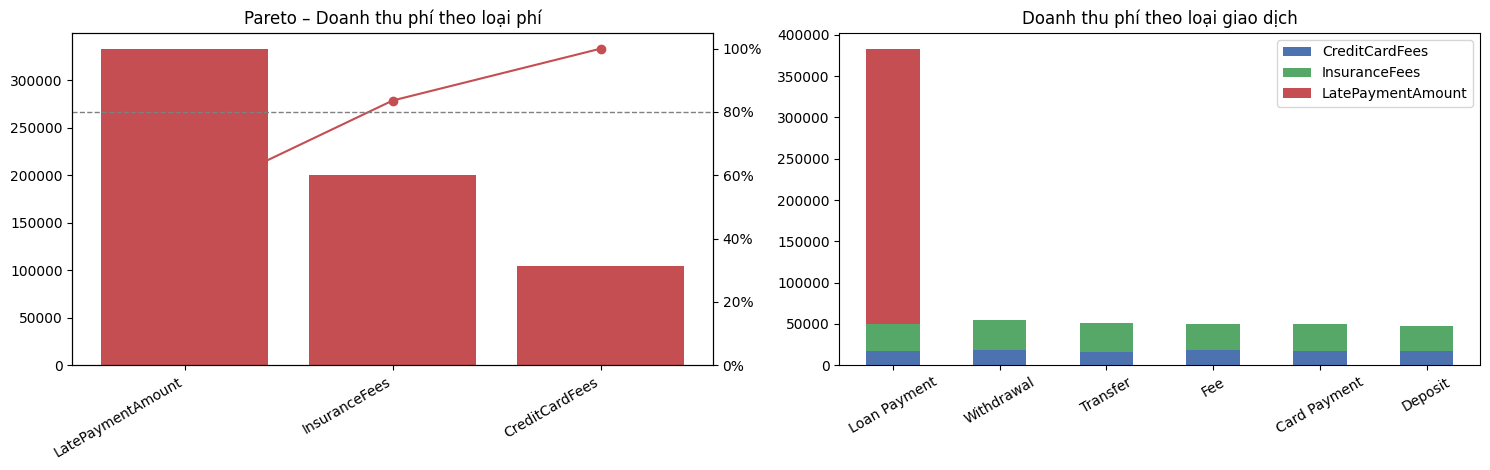

In [ ]:
fee_total = df[FEE_COLS].sum()
print('Tổng doanh thu phí:', f'{fee_total.sum():,.0f}')
display(fee_total.to_frame('Tong_Phi').assign(**{'%': lambda d: d.Tong_Phi / d.Tong_Phi.sum() * 100}))

# Doanh thu phí theo TransactionType × loại phí
fee_by_type = df.groupby('TransactionType')[FEE_COLS].sum()
fee_by_type['Total'] = fee_by_type.sum(axis=1)
fee_by_type['%'] = fee_by_type.Total / fee_by_type.Total.sum() * 100
display(fee_by_type.sort_values('Total', ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
pareto_chart(fee_total, 'Pareto – Doanh thu phí theo loại phí', ax[0], '#C44E52')
fee_by_type[FEE_COLS].loc[fee_by_type.Total.sort_values(ascending=False).index].plot(kind='bar', stacked=True, ax=ax[1], color=['#4C72B0', '#55A868', '#C44E52'])
ax[1].set_title('Doanh thu phí theo loại giao dịch'); ax[1].tick_params(axis='x', rotation=30); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

In [ ]:
# Pareto theo cặp (Loại phí × Loại giao dịch) và theo sản phẩm
pairs = df.melt(id_vars=['TransactionType', 'ProductCategory', 'ProductSubcategory'], value_vars=FEE_COLS, var_name='FeeType', value_name='Fee')
pairs = pairs[pairs.Fee > 0]
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
t_pair = pareto_chart(pairs.assign(K=pairs.FeeType.str.replace('Fees', '').str.replace('Amount', '') + ' | ' + pairs.TransactionType).groupby('K').Fee.sum(),
                      'Pareto – Loại phí | Loại giao dịch', ax[0], '#C44E52')
pareto_chart(df.groupby('ProductCategory').TotalFees.sum(), 'Pareto – Doanh thu phí theo nhóm sản phẩm', ax[1], '#8172B2')
plt.tight_layout(); plt.show()
print('Số cặp đạt 80% doanh thu phí:', (t_pair['Cum_%'] < 80).sum() + 1, '/', len(t_pair))
t_pair.head(6)


> ### 💡 Nhận xét 3.1
> - Tổng doanh thu phí ~**637 nghìn**, trong đó **LatePaymentAmount 52,3%**, InsuranceFees 31,3%, CreditCardFees 16,4% → chỉ **2/3 loại phí đã chiếm 83,6%** (Pareto 80/20 *có* xuất hiện ở đây).
> - Theo loại giao dịch: **Loan Payment tạo ~60,2%** doanh thu phí (~383 nghìn), 5 loại còn lại mỗi loại chỉ ~7,5–8,7%. Một cặp duy nhất *LatePayment | Loan Payment* đã là 52,3% tổng doanh thu phí.
> - Theo sản phẩm: **Loan 41,2%** và **Credit Card 27,3%** (phí thẻ chỉ phát sinh ở Credit Card, phí bảo hiểm chỉ ở Loan).
> - Rủi ro tập trung: doanh thu phí **phụ thuộc rất lớn vào khoản phạt/phí trên Loan Payment** – hiệu quả về ngắn hạn nhưng nhạy cảm về pháp lý/uy tín nếu bị xem là phí phạt quá mức.


### 3.3.2 Có nhóm khách hàng nào đang phải chịu mức chi phí không tương xứng?
**Phương pháp:** **Burden Index** = (% tổng phí của nhóm) ÷ (% tổng giá trị giao dịch của nhóm). Chỉ số **> 1** nghĩa là nhóm chịu phí *vượt* tỷ trọng giao dịch của mình. Kết hợp **RFM** để biết nhóm đó là khách giá trị cao hay thấp.

In [ ]:
bi_seg   = burden_index('CustomerSegment').reindex(SEGMENT_ORDER)
bi_score = burden_index('ScoreBand').reindex(SCORE_ORDER)
bi_sub   = burden_index('ProductSubcategory')
bi_cat   = burden_index('ProductCategory')
for n, t in [('Phân khúc thu nhập', bi_seg), ('Nhóm điểm tín dụng', bi_score), ('Hạng sản phẩm', bi_sub), ('Nhóm sản phẩm', bi_cat)]:
    print(f'===== {n} ====='); display(t[['Txn', 'Fee_per_Txn', 'Fee_rate_%', 'Fee_to_Income_%', 'Burden_Index']])

===== Phân khúc thu nhập =====


,Txn,Fee_per_Txn,Fee_rate_%,Fee_to_Income_%,Burden_Index
CustomerSegment,,,,,
Low Income Segment,4489,31.272816,0.633823,1.682946,1.004780
Middle Income Segment,8885,32.257284,0.629654,0.686484,0.998172
High Income Segment,6626,31.719069,0.630379,0.376736,0.999321


===== Nhóm điểm tín dụng =====


,Txn,Fee_per_Txn,Fee_rate_%,Fee_to_Income_%,Burden_Index
ScoreBand,,,,,
Poor (300-579),10139,31.177187,0.612614,0.779327,0.971159
Fair (580-669),3215,33.133760,0.669597,0.853686,1.061492
Good (670-739),2573,32.197738,0.640077,0.842009,1.014696
Very Good (740-799),2213,31.516941,0.623494,0.823377,0.988407
Excellent (800+),1860,33.299935,0.661063,0.814833,1.047963


===== Hạng sản phẩm =====


,Txn,Fee_per_Txn,Fee_rate_%,Fee_to_Income_%,Burden_Index
ProductSubcategory,,,,,
Business,4072,32.858283,0.638653,0.854247,1.012437
Gold,3956,31.952803,0.640898,0.792343,1.015996
Platinum,3965,32.395738,0.645638,0.767592,1.023511
Standard,3909,30.310246,0.602067,0.795948,0.954439
Student,4098,31.728677,0.626335,0.825412,0.992910


===== Nhóm sản phẩm =====


,Txn,Fee_per_Txn,Fee_rate_%,Fee_to_Income_%,Burden_Index
ProductCategory,,,,,
Checking Account,3888,18.526728,0.475425,0.472599,0.753677
Credit Card,4082,42.545845,0.859703,1.064722,1.362861
Loan,3998,65.608899,1.038756,1.676939,1.646709
Mortgage,3990,15.517792,0.204329,0.389298,0.323916
Savings Account,4042,16.634280,0.665654,0.422822,1.055241


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a, (t, ttl) in zip(ax, [(bi_seg, 'Phân khúc thu nhập'), (bi_score, 'Nhóm điểm tín dụng'), (bi_sub, 'Hạng sản phẩm')]):
    a.bar([str(i).replace(' Segment', '') for i in t.index], t.Burden_Index, color='#C44E52')
    a.axhline(1, color='black', ls='--'); a.set_title(f'Burden Index – {ttl}'); a.tick_params(axis='x', rotation=25)
    a.set_ylim(0, max(1.3, t.Burden_Index.max() * 1.15))
plt.tight_layout(); plt.show()

# Gánh nặng phí so với thu nhập (đây là chỉ số "không tương xứng" rõ nhất)
plt.figure(figsize=(8, 4))
sns.barplot(x=[s.replace(' Segment', '') for s in bi_seg.index], y=bi_seg['Fee_to_Income_%'], palette='Reds'); plt.title('Phí trung bình / Thu nhập tháng (%) theo phân khúc'); plt.show()

In [ ]:
# Kết hợp RFM: khách hàng tạo nhiều giá trị nhưng trả phí thấp / ít giá trị nhưng trả phí cao
rfm_fee = rfm.groupby('RFM_Segment').agg(Monetary=('Monetary', 'sum'), Fees=('Fees', 'sum'), So_KH=('Fees', 'size')).reindex(labels)
rfm_fee['Burden_Index']  = (rfm_fee.Fees / rfm_fee.Fees.sum()) / (rfm_fee.Monetary / rfm_fee.Monetary.sum())
rfm_fee['Phi_TB_moi_KH'] = rfm_fee.Fees / rfm_fee.So_KH
rfm_fee


> ### 💡 Nhận xét 3.2
> - **Gánh nặng phí so với thu nhập là bất tương xứng rõ nhất:** phí/GD gần như phẳng giữa các phân khúc (~31–32) nên *Burden Index ≈ 1,00* ở cả 3 phân khúc, nhưng **phí/thu nhập tháng: Low 1,68% vs Middle 0,69% vs High 0,38% (gấp ~4,4 lần)** → cấu trúc phí mang tính **lũy thoái** với nhóm thu nhập thấp.
> - Theo sản phẩm: **Loan (Burden Index 1,65; phí ~65,6/GD)** và **Credit Card (1,36; ~42,6/GD)** chịu phí vượt tỷ trọng giá trị; Mortgage (0,32) và Checking (0,75) thấp. Điểm tín dụng và hạng sản phẩm (Student/Gold…) **không** tạo khác biệt (Burden Index 0,95–1,06).
> - Kết hợp RFM: các nhóm giá trị thấp–trung bình trả phí vượt tỷ trọng: **About to Sleep (1,23)**, **Potential Loyalists (1,16)**, **Hibernating/Lost (1,16)**; ngược lại nhóm giá trị cao (**Champions 0,96, At Risk 0,88, Loyal 0,91**) trả ít hơn tỷ trọng. Rủi ro: khách giá trị thấp chịu phí cao dễ rời bỏ.
> - Hành động: xem xét trần/ưu đãi phí cho nhóm thu nhập thấp và khách có Loan; kết nối với offer *Financial Literacy* (xem 4.2).


### 3.2.3 Đâu là những nguồn "ma sát" (friction) thường xuyên nhất nhưng lại tạo ra doanh thu?
**Phương pháp:** Đo **tần suất xảy ra** (tỷ lệ giao dịch phát sinh phí) và **doanh thu mỗi lần xảy ra**; dùng **Funnel** để xem mức độ "ma sát lặp lại" ở cấp khách hàng.
> Dữ liệu không có cột trạng thái giao dịch (thành công/thất bại), nên Funnel được áp dụng theo hướng **funnel phí**: tất cả giao dịch → giao dịch bị tính phí → bị tính ≥2 loại phí; và tất cả khách hàng → khách bị tính phí lặp lại (≥1, ≥2, ≥3 lần).

In [ ]:
# Tần suất & doanh thu / lần của từng loại phí (theo loại giao dịch & kênh)
rows = []
for fee in FEE_COLS:
    for dim in ['TransactionType', 'Channel', 'ProductCategory']:
        g = df.groupby(dim).agg(N=(fee, 'size'), Events=(fee, lambda x: (x > 0).sum()), Revenue=(fee, 'sum'))
        g = g[g.Events > 0]
        for k, r in g.iterrows():
            rows.append({'FeeType': fee, 'Dim': dim, 'Group': k, 'Frequency_%': r.Events / r.N * 100,
                         'Avg_per_event': r.Revenue / r.Events, 'Revenue': r.Revenue})
fr = pd.DataFrame(rows)

# Tổng quan: mỗi loại phí
overview = pd.DataFrame({
    'Frequency_% (tỷ lệ GD bị tính phí)': [(df[f] > 0).mean() * 100 for f in FEE_COLS],
    'Avg_per_event': [df.loc[df[f] > 0, f].mean() for f in FEE_COLS],
    'Revenue': [df[f].sum() for f in FEE_COLS]}, index=FEE_COLS)
display(overview)

fig = px.scatter(fr[fr.Dim == 'TransactionType'], x='Frequency_%', y='Avg_per_event', size='Revenue', color='FeeType',
                 hover_name='Group', title='Ma sát: tần suất vs doanh thu mỗi lần (kích thước = tổng doanh thu) – theo loại giao dịch', height=450)
fig.show()

,Frequency_% (tỷ lệ GD bị tính phí),Avg_per_event,Revenue
CreditCardFees,20.410,25.575189,104397.92
InsuranceFees,19.990,49.943527,199674.22
LatePaymentAmount,16.845,98.868522,333088.05


In [ ]:
# ---- Funnel 1: cấp GIAO DỊCH (chuỗi lồng nhau) ----
n_fee = df.HasFee.sum()
n_two = ((df[FEE_COLS] > 0).sum(axis=1) >= 2).sum()
fig = go.Figure(go.Funnel(y=['Tất cả giao dịch', 'Có ≥1 loại phí', 'Có ≥2 loại phí cùng lúc'],
                          x=[len(df), n_fee, n_two], textinfo='value+percent initial+percent previous'))
fig.update_layout(title='Funnel phí – cấp giao dịch', height=360); fig.show()

# ---- Funnel 2: cấp KHÁCH HÀNG – ma sát lặp lại ----
cust_fee_events = df[df.HasFee].groupby('CustomerID').size()
n_c = df.CustomerID.nunique()
fig = go.Figure(go.Funnel(y=['Tất cả khách hàng', 'Từng bị tính phí ≥1 lần', 'Bị tính phí ≥2 lần', 'Bị tính phí ≥3 lần'],
                          x=[n_c, (cust_fee_events >= 1).sum(), (cust_fee_events >= 2).sum(), (cust_fee_events >= 3).sum()],
                          textinfo='value+percent initial+percent previous'))
fig.update_layout(title='Funnel phí – cấp khách hàng (ma sát lặp lại)', height=400); fig.show()

# ---- Funnel 3: khách hàng & khoản phí trên Loan Payment (nguồn phí lớn nhất) ----
cust_loanpay = df[df.LatePaymentAmount > 0].groupby('CustomerID').size()
fig = go.Figure(go.Funnel(y=['Tất cả khách hàng', 'Có ≥1 Loan Payment (bị tính phí)', 'Có ≥2 Loan Payment', 'Có ≥3 Loan Payment'],
                          x=[n_c, (cust_loanpay >= 1).sum(), (cust_loanpay >= 2).sum(), (cust_loanpay >= 3).sum()],
                          textinfo='value+percent initial+percent previous'))
fig.update_layout(title='Funnel Loan Payment – khách hàng lặp lại khoản phí lớn nhất', height=400); fig.show()

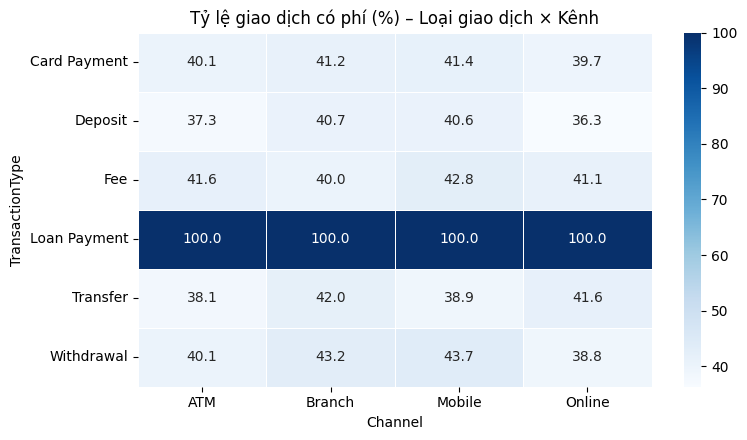

Loan Payment: 100.0% giao dịch có LatePaymentAmount; mức TB = 98.9
Phí theo nhóm sản phẩm:


,CreditCardFees,InsuranceFees,LatePaymentAmount
ProductCategory,,,
Checking Account,0.00,0.00,72031.92
Credit Card,104397.92,0.00,69274.22
Loan,0.00,199674.22,62630.16
Mortgage,0.00,0.00,61915.99
Savings Account,0.00,0.00,67235.76


In [ ]:
# Ma sát theo kênh & loại giao dịch: tỷ lệ giao dịch phát sinh phí (%)
heat(df.pivot_table(index='TransactionType', columns='Channel', values='HasFee', aggfunc='mean') * 100,
     'Tỷ lệ giao dịch có phí (%) – Loại giao dịch × Kênh', figsize=(8, 4.5))
late_loan = df[df.TransactionType == 'Loan Payment']
print(f"Loan Payment: {(late_loan.LatePaymentAmount>0).mean():.1%} giao dịch có LatePaymentAmount; mức TB = {late_loan.loc[late_loan.LatePaymentAmount>0,'LatePaymentAmount'].mean():,.1f}")
print('Phí theo nhóm sản phẩm:'); display(df.groupby('ProductCategory')[FEE_COLS].sum())


> ### 💡 Nhận xét 3.3
> - **Nguồn ma sát lớn nhất và sinh nhiều tiền nhất là khoản `LatePaymentAmount` trên Loan Payment:** xuất hiện ở ~16,8% giao dịch với mức trung bình ~98,9/lần (cao gấp ~2 lần phí bảo hiểm ~49,9 và ~3,9 lần phí thẻ ~25,6). Dữ liệu cho thấy **100% giao dịch Loan Payment đều có khoản này** → thực chất là một cơ chế tính phí gắn với loại giao dịch hơn là hiện tượng trễ hạn ngẫu nhiên.
> - Phí bảo hiểm và phí thẻ tần suất cao hơn (~20%/giao dịch) nhưng giá trị mỗi lần thấp hơn.
> - **Funnel phí (giao dịch):** 20.000 GD → 10.106 có ≥1 loại phí (50,5%) → chỉ 1.343 có ≥2 loại phí (6,7%).
> - **Funnel phí (khách hàng):** 8.025 KH → 6.082 từng bị tính phí (75,8%) → 2.778 bị ≥2 lần (34,6%) → 938 bị ≥3 lần (11,7%). Đây là nhóm "ma sát lặp lại" cần theo dõi churn.
> - **Funnel Loan Payment:** 2.789 KH (34,8%) có ít nhất 1 Loan Payment → 502 (6,3%) có ≥2 → 68 (0,8%) có ≥3: khoản phí lớn nhất hầu như chỉ đánh vào khách *một lần*, nên doanh thu này mang tính "một lần" hơn là bền vững.
> - Kênh không ảnh hưởng đến tỷ lệ phát sinh phí (49,4–51,4%).


## 3.4 PHÂN TÍCH XU HƯỚNG & HIỆU SUẤT

### 3.4.1 Có tháng hoặc mùa nào phản ánh đỉnh điểm / sụt giảm của giao dịch?
**Phương pháp:** Thống kê mô tả chuỗi thời gian. Dùng **số giao dịch / ngày** (thay vì tổng) để loại bỏ hiệu ứng tháng có ít ngày (đặc biệt tháng 2); **loại tháng 05/2025** vì chưa đủ dữ liệu.

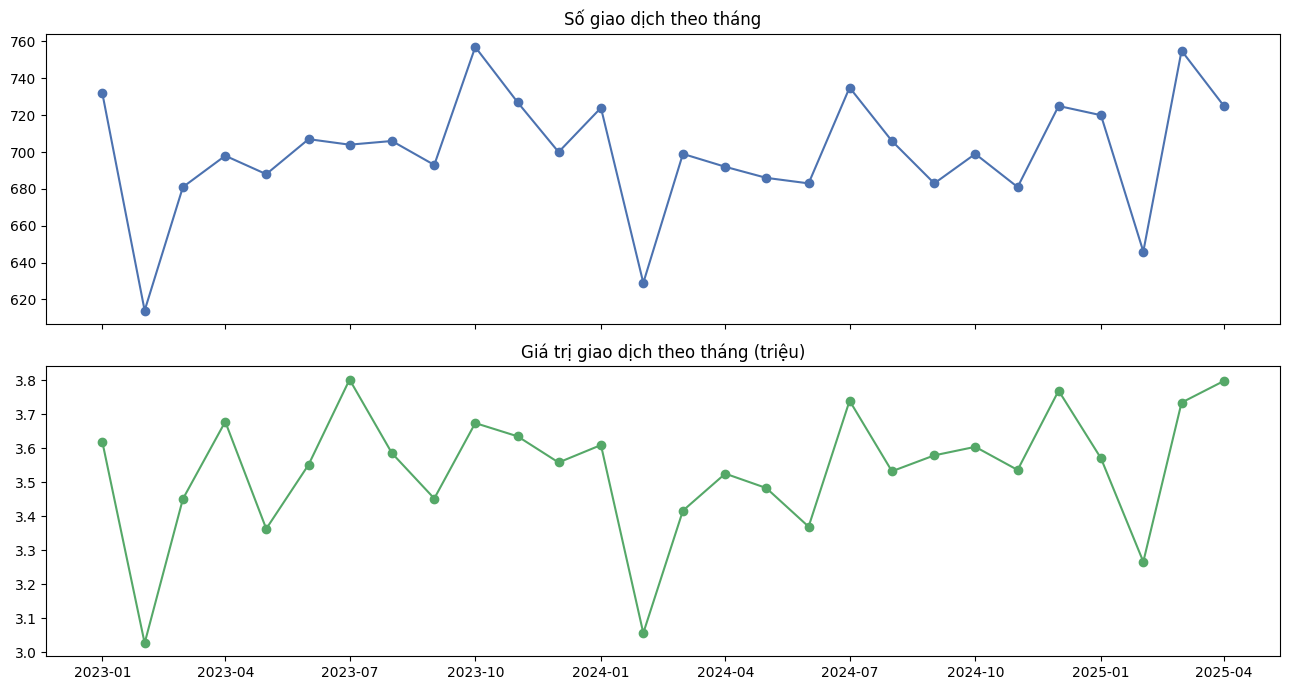

In [ ]:
full = df[df.YearMonth <= LAST_FULL_MONTH].copy()
monthly = full.groupby('YearMonth').agg(So_GD=('TransactionID', 'count'), Tong_GiaTri=('Amount', 'sum'), Tong_Phi=('TotalFees', 'sum'))
monthly['Ngay'] = monthly.index.days_in_month
monthly['GD_moi_ngay'] = monthly.So_GD / monthly.Ngay
monthly['Index_mua_vu'] = monthly.GD_moi_ngay / monthly.GD_moi_ngay.mean() * 100
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(monthly.index, monthly.So_GD, marker='o', color='#4C72B0'); ax[0].set_title('Số giao dịch theo tháng')
ax[1].plot(monthly.index, monthly.Tong_GiaTri / 1e6, marker='o', color='#55A868'); ax[1].set_title('Giá trị giao dịch theo tháng (triệu)')
plt.tight_layout(); plt.show()

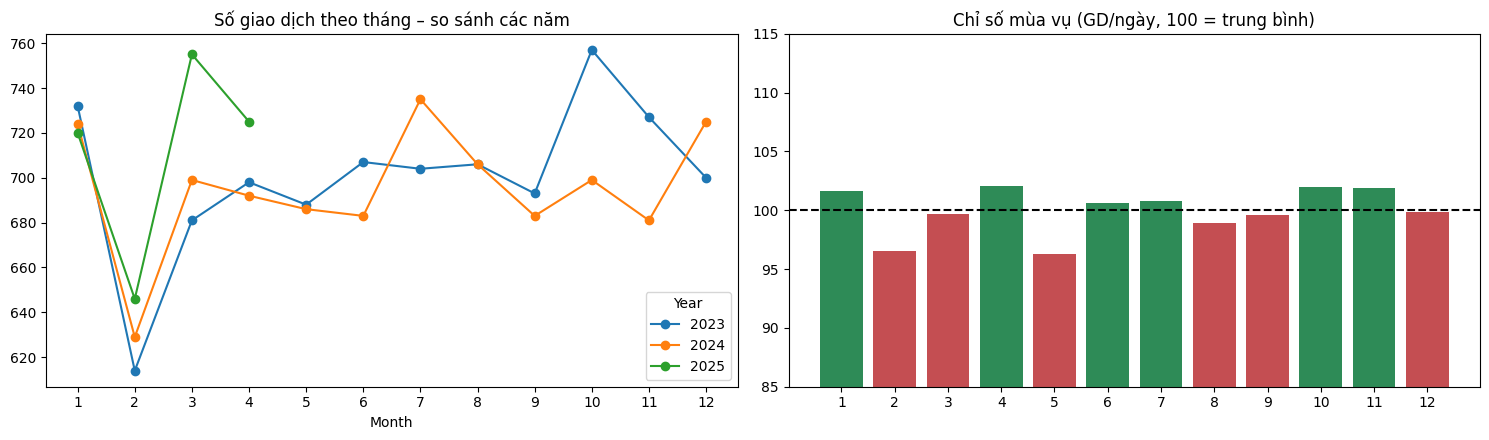

Top 3 tháng cao nhất (chỉ số mùa vụ):
YearMonth
4     102.1
10    102.0
11    101.9

Top 3 tháng thấp nhất:
YearMonth
5    96.3
2    96.6
8    98.9


,So_GD,So_Thang,Tong_GiaTri,GD_moi_thang,GiaTri_moi_thang
Season,,,,,
Xuân,5624,8,2.845040e+07,703.000000,3.556300e+06
Hè,4241,6,2.158128e+07,706.833333,3.596880e+06
Thu,4240,6,2.148140e+07,706.666667,3.580233e+06
Đông,5490,8,2.747811e+07,686.250000,3.434764e+06



Kruskal-Wallis (GD/ngày theo tháng): H = 7.40, p = 0.7658 → KHÔNG có tính mùa vụ đáng kể (dao động trong ngưỡng ngẫu nhiên)


In [ ]:
# So sánh các năm theo tháng + chỉ số mùa vụ
pv = full.pivot_table(index='Month', columns='Year', values='TransactionID', aggfunc='count')
pv_day = pv.div(pd.Series(range(1, 13), index=range(1, 13)).map(lambda m: pd.Period(f'2024-{m:02d}').days_in_month), axis=0)

seasonal = (monthly.groupby(monthly.index.month).Index_mua_vu.mean()).rename('Seasonal_Index')
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pv.plot(marker='o', ax=ax[0]); ax[0].set_title('Số giao dịch theo tháng – so sánh các năm'); ax[0].set_xticks(range(1, 13))
ax[1].bar(seasonal.index, seasonal.values, color=np.where(seasonal.values >= 100, '#2E8B57', '#C44E52')); ax[1].axhline(100, color='black', ls='--')
ax[1].set_title('Chỉ số mùa vụ (GD/ngày, 100 = trung bình)'); ax[1].set_xticks(range(1, 13)); ax[1].set_ylim(85, 115)
plt.tight_layout(); plt.show()

print('Top 3 tháng cao nhất (chỉ số mùa vụ):'); print(seasonal.sort_values(ascending=False).head(3).round(1).to_string())
print('\nTop 3 tháng thấp nhất:');               print(seasonal.sort_values().head(3).round(1).to_string())
season_tbl = full.groupby('Season').agg(So_GD=('TransactionID', 'count'), So_Thang=('YearMonth', 'nunique'), Tong_GiaTri=('Amount', 'sum'))
season_tbl['GD_moi_thang'] = season_tbl.So_GD / season_tbl.So_Thang
season_tbl['GiaTri_moi_thang'] = season_tbl.Tong_GiaTri / season_tbl.So_Thang
display(season_tbl.reindex(['Xuân', 'Hè', 'Thu', 'Đông']))

# Kiểm định: số giao dịch MỖI NGÀY có khác nhau giữa các tháng trong năm không?
daily = full.groupby('TransactionDate').size().reindex(pd.date_range(full.TransactionDate.min(), full.TransactionDate.max()), fill_value=0)
h, p = stats.kruskal(*[g.values for _, g in daily.groupby(daily.index.month)])
print(f'\nKruskal-Wallis (GD/ngày theo tháng): H = {h:.2f}, p = {p:.4f} →', 'Có tính mùa vụ' if p < 0.05 else 'KHÔNG có tính mùa vụ đáng kể (dao động trong ngưỡng ngẫu nhiên)')

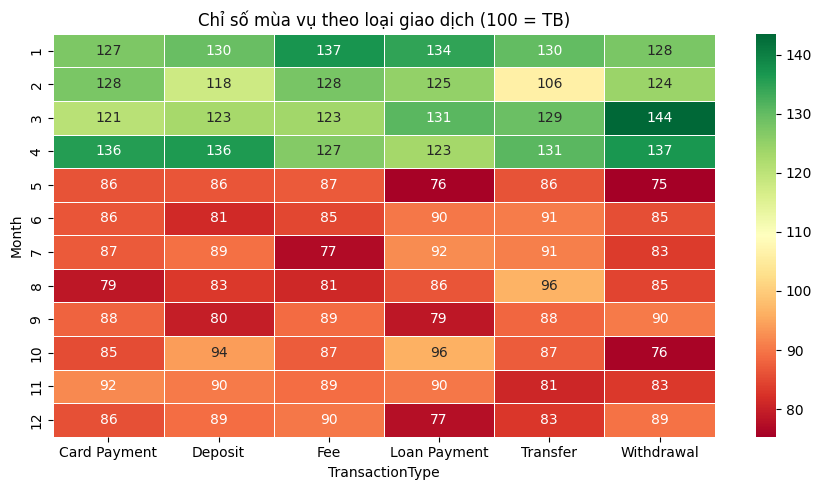

In [ ]:
# Heatmap: tháng × loại giao dịch (số GD/ngày, chuẩn hoá theo trung bình từng loại)
hm = full.pivot_table(index='Month', columns='TransactionType', values='TransactionID', aggfunc='count')
hm = hm.div(hm.index.map(lambda m: pd.Period(f'2024-{m:02d}').days_in_month), axis=0)
hm = hm / hm.mean() * 100
heat(hm, 'Chỉ số mùa vụ theo loại giao dịch (100 = TB)', fmt='.0f', cmap='RdYlGn', figsize=(9, 5))


> ### 💡 Nhận xét 4.1
> - Chuỗi giao dịch khá ổn định ~690–750 GD/tháng. Đỉnh thô: **10/2023 (757 GD)**; đáy thô: **02/2023 (614 GD)** – nhưng đáy tháng 2 chủ yếu do tháng ngắn ngày (sau khi chuẩn hoá theo số ngày, chỉ số mùa vụ tháng 2 = ~96,6).
> - Chỉ số mùa vụ (GD/ngày, 100 = TB) dao động hẹp **96–102**: cao nhất *Tháng 4 (102,1), Tháng 10 (102,0), Tháng 11 (101,9)*; thấp nhất *Tháng 5 (96,3), Tháng 2 (96,6), Tháng 8 (98,9)*.
> - Theo mùa: Xuân ~703, Hè ~707, Thu ~707, Đông ~686 GD/tháng (Đông thấp hơn ~3%).
> - **Kiểm định Kruskal-Wallis p ≈ 0,77 → không có tính mùa vụ đáng kể.** Các "đỉnh/đáy" ở trên nằm trong dao động ngẫu nhiên, nên không nên lập kế hoạch nhân sự/thanh khoản theo mùa dựa trên dữ liệu này.
> - ⚠️ Tháng 05/2025 chỉ có dữ liệu đến 20/05 nên đã bị loại khỏi phân tích.


### 3.4.2 Các đề xuất sản phẩm (offer) có thực sự phù hợp với nhu cầu và hành vi thực tế của khách hàng?
**Phương pháp:** (1) **Sankey** + giải mã *quy tắc gán offer* → (2) kiểm tra offer có phản ứng với **hành vi thực tế** không → (3) đo độ khớp **offer ↔ sản phẩm khách đang dùng** → (4) **Market Basket** tìm các nhóm sản phẩm hay đi cùng nhau → (5) **Funnel Product Holdings** (mức độ bán chéo).

In [ ]:
# (1) Offer được gán dựa trên điều gì? → thử gom theo (Phân khúc × Nhóm sản phẩm)
rule = df.groupby(['CustomerSegment', 'ProductCategory']).RecommendedOffer.agg(Offer='first', So_Offer_khac_nhau='nunique').loc[SEGMENT_ORDER]
display(rule)
print('Mỗi cặp (Phân khúc × Nhóm SP) chỉ ứng với đúng 1 offer?', (rule.So_Offer_khac_nhau == 1).all())
draw_sankey(df, ['CustomerSegment', 'RecommendedOffer', 'ProductCategory'], 'Sankey: Phân khúc → Offer đề xuất → Sản phẩm khách đang dùng')

Offer  \
CustomerSegment       ProductCategory                                       
Low Income Segment    Checking Account  Financial Literacy Program Access   
                      Credit Card       Financial Literacy Program Access   
                      Loan              Financial Literacy Program Access   
                      Mortgage          Financial Literacy Program Access   
                      Savings Account                No-Fee Basic Account   
Middle Income Segment Checking Account           Mid-tier Savings Booster   
                      Credit Card          Gold Card with Travel Benefits   
                      Loan                   Personal Loan Cashback Offer   
                      Mortgage                   Mid-tier Savings Booster   
                      Savings Account            Mid-tier Savings Booster   
High Income Segment   Checking Account        Premium Investment Services   
                      Credit Card              Exclusive Platinum Package   
                      Loan                    Premium Investment Services   
                      Mortgage                 Exclusive Platinum Package   
                      Savings Account         Premium Investment Services   

                                        So_Offer_khac_nhau  
CustomerSegment       ProductCategory                       
Low Income Segment    Checking Account                   1  
                      Credit Card                        1  
                      Loan                               1  
                      Mortgage                           1  
                      Savings Account                    1  
Middle Income Segment Checking Account                   1  
                      Credit Card                        1  
                      Loan                               1  
                      Mortgage                           1  
                      Savings Account                    1  
High Income Segment   Checking Account                   1  
                      Credit Card                        1  
                      Loan                               1  
                      Mortgage                           1  
                      Savings Account                    1

Mỗi cặp (Phân khúc × Nhóm SP) chỉ ứng với đúng 1 offer? True


In [ ]:
# (2) Offer có phản ứng với HÀNH VI thực tế không?
# (a) Một khách nhận bao nhiêu offer khác nhau?
co = df.groupby('CustomerID').agg(n=('TransactionID', 'count'), n_offers=('RecommendedOffer', 'nunique'))
multi = co[co.n >= 2]
print(f"(a) Khách có >=2 giao dịch: {(multi.n_offers > 1).mean():.1%} nhận >=2 offer khác nhau (TB {multi.n_offers.mean():.2f} offer / khách)")

# (b) Các tín hiệu hành vi có khác nhau giữa các nhóm offer không? (Kruskal-Wallis / χ²)
for col in ['CustomerScore', 'Amount', 'TotalFees']:
    h, p = stats.kruskal(*[g[col].values for _, g in df.groupby('RecommendedOffer')])
    print(f"(b) {col:14s} theo offer: p = {p:.4f} →", 'khác biệt' if p < 0.05 else 'không khác biệt')
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df.RecommendedOffer, df.Channel))
print(f"(b) Channel         theo offer: p = {p:.4f} →", 'khác biệt' if p < 0.05 else 'không khác biệt')
print('\nHành vi trung bình theo offer:')
display(df.groupby('RecommendedOffer').agg(So_GD=('TransactionID', 'count'), Score_TB=('CustomerScore', 'mean'), Income_TB=('MonthlyIncome', 'mean'),
                                          Amount_TB=('Amount', 'mean'), Phi_TB=('TotalFees', 'mean')))

(a) Khách có >=2 giao dịch: 91.5% nhận >=2 offer khác nhau (TB 2.46 offer / khách)
(b) CustomerScore  theo offer: p = 0.4574 → không khác biệt
(b) Amount         theo offer: p = 0.0000 → khác biệt
(b) TotalFees      theo offer: p = 0.0000 → khác biệt
(b) Channel         theo offer: p = 0.6263 → không khác biệt

Hành vi trung bình theo offer:


,So_GD,Score_TB,Income_TB,Amount_TB,Phi_TB
RecommendedOffer,,,,,
Exclusive Platinum Package,2672,572.217814,8524.439180,6254.445177,29.292425
Financial Literacy Program Access,3540,576.403107,2007.072983,5571.088690,35.411469
Gold Card with Travel Benefits,1837,570.045727,4964.714594,4967.458684,42.734812
Mid-tier Savings Booster,5220,575.380843,5005.059391,4764.198549,17.086077
No-Fee Basic Account,949,578.105374,2001.076270,2557.510004,15.834636
Personal Loan Cashback Offer,1828,573.496718,4960.796532,6303.981832,65.050766
Premium Investment Services,3954,578.877086,8498.394985,4205.482312,33.358925


,Sản phẩm liên quan,So_GD,Tỷ lệ GD khớp %,Kỳ vọng nếu ngẫu nhiên %,Lift
Offer,,,,,
Personal Loan Cashback Offer,Loan,1828,100.000000,19.99,5.002501
Gold Card with Travel Benefits,Credit Card,1837,100.000000,20.41,4.899559
Exclusive Platinum Package,Credit Card,2672,50.449102,20.41,2.471784
Premium Investment Services,Savings Account,3954,34.294385,20.21,1.696902
Mid-tier Savings Booster,Savings Account,5220,33.275862,20.21,1.646505
Financial Literacy Program Access,"Loan, Credit Card",3540,49.774011,40.40,1.232030
No-Fee Basic Account,Checking Account,949,0.000000,19.44,0.000000


Tỷ lệ giao dịch có offer 'khớp chủ đề' với sản phẩm đang dùng: 49.3%


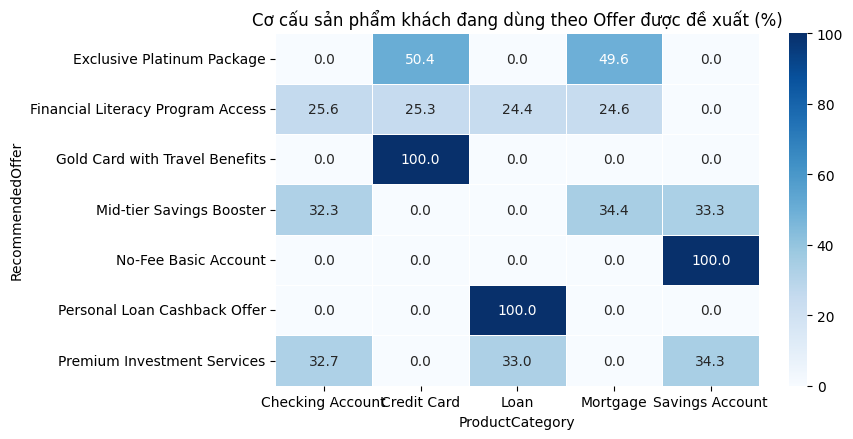

In [ ]:
# (3) Mức độ khớp Offer ↔ Sản phẩm đang dùng
# ⚠️ GIẢ ĐỊNH (có thể chỉnh): nhóm sản phẩm "liên quan" tới từng offer
OFFER_TARGET = {
    'No-Fee Basic Account':               ['Checking Account'],
    'Mid-tier Savings Booster':           ['Savings Account'],
    'Premium Investment Services':        ['Savings Account'],            # dataset không có nhóm đầu tư → dùng Savings làm proxy
    'Financial Literacy Program Access':  ['Loan', 'Credit Card'],        # nhóm dễ phát sinh nợ / phí
    'Exclusive Platinum Package':         ['Credit Card'],
    'Gold Card with Travel Benefits':     ['Credit Card'],
    'Personal Loan Cashback Offer':       ['Loan'],
}
base = df.ProductCategory.value_counts(normalize=True)          # xác suất ngẫu nhiên

rows = []
for offer, cats in OFFER_TARGET.items():
    sub = df[df.RecommendedOffer == offer]
    match = sub.ProductCategory.isin(cats).mean()
    expected = base[cats].sum()
    rows.append({'Offer': offer, 'Sản phẩm liên quan': ', '.join(cats), 'So_GD': len(sub),
                 'Tỷ lệ GD khớp %': match * 100, 'Kỳ vọng nếu ngẫu nhiên %': expected * 100, 'Lift': match / expected})
fit = pd.DataFrame(rows).set_index('Offer').sort_values('Lift', ascending=False)
display(fit)
print(f"Tỷ lệ giao dịch có offer 'khớp chủ đề' với sản phẩm đang dùng: {sum(df.RecommendedOffer.eq(o) & df.ProductCategory.isin(c) for o, c in OFFER_TARGET.items()).sum() / len(df):.1%}")

mix = pd.crosstab(df.RecommendedOffer, df.ProductCategory, normalize='index') * 100
heat(mix, 'Cơ cấu sản phẩm khách đang dùng theo Offer được đề xuất (%)', figsize=(9, 4.5))

In [ ]:
# (4) MARKET BASKET ANALYSIS – "giỏ hàng" = tập các nhóm sản phẩm mà 1 khách hàng đã dùng
def run_mba(item_col, min_support=0.02, min_lift=0.0):    # min_lift=0 để thấy cả luật có lift < 1 (nhóm sản phẩm loại trừ nhau)
    basket = (df.groupby(['CustomerID', item_col]).size().unstack(fill_value=0) > 0)
    freq = apriori(basket, min_support=min_support, use_colnames=True)
    rules = association_rules(freq, metric='lift', min_threshold=min_lift)
    rules = rules[(rules.antecedents.map(len) == 1) & (rules.consequents.map(len) == 1)].copy()
    rules['antecedents'] = rules.antecedents.map(lambda s: ', '.join(s)); rules['consequents'] = rules.consequents.map(lambda s: ', '.join(s))
    return basket, rules.sort_values('lift', ascending=False)[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

basket, rules_cat = run_mba('ProductCategory', min_support=0.05)
print(f'Số giỏ hàng (khách): {len(basket):,} | Số nhóm sản phẩm trung bình / khách: {basket.sum(axis=1).mean():.2f}')
print('\nCác luật kết hợp (ProductCategory) – sắp xếp theo lift:')
display(rules_cat.head(10))
print(f'Lift lớn nhất = {rules_cat.lift.max():.2f} | lift trung bình = {rules_cat.lift.mean():.2f}  (lift < 1: hai nhóm SP ít đi cùng nhau hơn mức ngẫu nhiên)')

# Mức độ phổ biến của từng nhóm sản phẩm trong giỏ
sup = basket.mean().sort_values(ascending=False) * 100
print('\nSupport từng nhóm sản phẩm (% khách hàng có dùng):'); print(sup.round(1).to_string())

Số giỏ hàng (khách): 8,025 | Số nhóm sản phẩm trung bình / khách: 2.01

Các luật kết hợp (ProductCategory) – sắp xếp theo lift:


,antecedents,consequents,support,confidence,lift
16,Savings Account,Loan,0.148785,0.369316,0.911367
17,Loan,Savings Account,0.148785,0.367159,0.911367
19,Mortgage,Savings Account,0.146542,0.364651,0.905142
18,Savings Account,Mortgage,0.146542,0.363749,0.905142
14,Mortgage,Loan,0.146791,0.365271,0.901384
15,Loan,Mortgage,0.146791,0.362239,0.901384
9,Loan,Credit Card,0.149159,0.368081,0.896465
8,Credit Card,Loan,0.149159,0.363278,0.896465
12,Credit Card,Savings Account,0.147414,0.359029,0.891187
13,Savings Account,Credit Card,0.147414,0.365914,0.891187


Lift lớn nhất = 0.91 | lift trung bình = 0.89  (lift < 1: hai nhóm SP ít đi cùng nhau hơn mức ngẫu nhiên)

Support từng nhóm sản phẩm (% khách hàng có dùng):
ProductCategory
Credit Card         41.1
Loan                40.5
Savings Account     40.3
Mortgage            40.2
Checking Account    39.4


Top 10 luật theo lift (Product_Tier):


,antecedents,consequents,support,confidence,lift
9,Loan | Standard,Mortgage | Student,0.011090,0.116798,1.183464
8,Mortgage | Student,Loan | Standard,0.011090,0.112374,1.183464
12,Mortgage | Platinum,Savings Account | Platinum,0.010592,0.113182,1.138207
13,Savings Account | Platinum,Mortgage | Platinum,0.010592,0.106516,1.138207
10,Loan | Student,Mortgage | Business,0.010093,0.107143,1.103750
11,Mortgage | Business,Loan | Student,0.010093,0.103979,1.103750
15,Mortgage | Standard,Savings Account | Student,0.010093,0.106439,1.085352
14,Savings Account | Student,Mortgage | Standard,0.010093,0.102922,1.085352
4,Credit Card | Student,Credit Card | Platinum,0.010841,0.105711,1.055136
5,Credit Card | Platinum,Credit Card | Student,0.010841,0.108209,1.055136


/tmp/ipykernel_1987/911287958.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




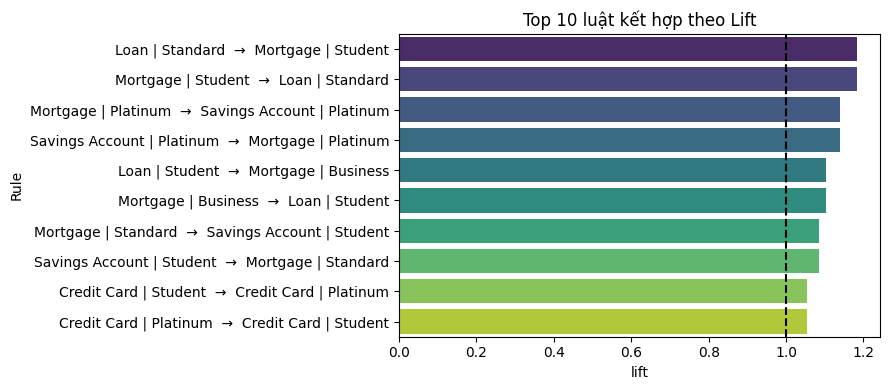

In [ ]:
# MBA mức chi tiết hơn: Nhóm sản phẩm + Hạng (VD: Credit Card | Platinum)
df['Product_Tier'] = df.ProductCategory + ' | ' + df.ProductSubcategory
_, rules_tier = run_mba('Product_Tier', min_support=0.01)
print('Top 10 luật theo lift (Product_Tier):'); display(rules_tier.head(10))

plt.figure(figsize=(9, 4))
top = rules_tier.head(10).assign(Rule=lambda d: d.antecedents + '  →  ' + d.consequents)
sns.barplot(data=top, y='Rule', x='lift', palette='viridis'); plt.axvline(1, color='black', ls='--'); plt.title('Top 10 luật kết hợp theo Lift'); plt.tight_layout(); plt.show()

In [ ]:
# (5) FUNNEL "Product Holdings": khách hàng đang giữ bao nhiêu nhóm sản phẩm? (thang bán chéo)
n_cat = rfm.NumCategories
steps = [('Tất cả khách hàng (≥1 nhóm SP)', (n_cat >= 1).sum()), ('Dùng ≥2 nhóm SP', (n_cat >= 2).sum()),
         ('Dùng ≥3 nhóm SP', (n_cat >= 3).sum()), ('Dùng ≥4 nhóm SP', (n_cat >= 4).sum()), ('Dùng đủ 5 nhóm SP', (n_cat >= 5).sum())]
fig = go.Figure(go.Funnel(y=[s[0] for s in steps], x=[s[1] for s in steps], textinfo='value+percent previous+percent initial'))
fig.update_layout(title='Funnel Product Holdings – mức độ bán chéo', height=420); fig.show()
print(f"Khách chỉ giao dịch 1 lần: {(rfm.Frequency == 1).mean():.1%} → không thể bán chéo nếu không kéo họ quay lại")

Khách chỉ giao dịch 1 lần: 27.1% → không thể bán chéo nếu không kéo họ quay lại



> ### 💡 Nhận xét 4.2
> **1) Offer được gán theo *quy tắc cố định*, không theo hành vi.** Mỗi cặp (Phân khúc × Nhóm sản phẩm) ứng với đúng **1 offer** (15 ô → 7 offer), VD: Middle + Credit Card → *Gold Card with Travel Benefits*; Middle + Loan → *Personal Loan Cashback*; Low + Savings → *No-Fee Basic Account*; High + Credit Card/Mortgage → *Exclusive Platinum*.
>
> **2) Bằng chứng offer không phản ứng với hành vi:** điểm tín dụng (p = 0,46) và kênh (p = 0,63) không khác nhau giữa các nhóm offer; phần khác biệt về Amount/phí chỉ do offer gắn với loại sản phẩm. Hơn nữa **91,5% khách có ≥2 giao dịch nhận ≥2 offer khác nhau** (TB 2,46 offer/khách) vì phân khúc/sản phẩm đổi theo từng giao dịch → trải nghiệm cá nhân hóa **không nhất quán**.
>
> **3) Độ khớp "chủ đề" offer ↔ sản phẩm đang dùng** (theo giả định `OFFER_TARGET`): *Personal Loan Cashback* và *Gold Card* khớp 100% (lift ~5), *Exclusive Platinum* 50,5% (lift 2,5), *Premium Investment* 34,3% và *Mid-tier Savings Booster* 33,3% (lift ~1,7), *Financial Literacy* 49,8% (lift 1,2). **No-Fee Basic Account khớp 0%** vì chỉ đề xuất cho khách Low-income đang dùng *Savings*, không phải *Checking*. Tổng thể chỉ ~49,3% giao dịch có offer khớp chủ đề.
>
> **4) Market Basket:** các cặp nhóm sản phẩm có **lift 0,89–0,91 (< 1)** → khách dùng nhóm này *ít* kéo theo nhóm kia hơn ngẫu nhiên. Ở cấp hạng sản phẩm lift tối đa chỉ ~1,18 với support ~1% và confidence ~11–12% → **không có combo/bán chéo tự nhiên nào đủ mạnh** để làm căn cứ cho offer.
>
> **5) Funnel Product Holdings:** 8.025 KH → 5.287 dùng ≥2 nhóm SP (65,9%) → 2.266 ≥3 (28,2%) → 544 ≥4 → chỉ 41 đủ 5 nhóm (0,5%); 27,1% khách chỉ giao dịch 1 lần.
>
> **Kết luận:** offer *phù hợp về mặt thu nhập và một phần theo sản phẩm* (Financial Literacy là hợp lý với nhóm Low-income chịu phí/thu nhập cao – xem 3.2), nhưng **chưa phù hợp với hành vi thực tế** do thiếu tín hiệu hành vi (tần suất, recency, điểm tín dụng, phí đã chịu) và thiếu bằng chứng bán chéo từ dữ liệu.


### 3.4.3 Những xu hướng nào mới nổi theo thời gian giữa các phân khúc hoặc kênh giao dịch?
**Phương pháp:** **Cohort Analysis** (giữ chân khách theo tháng giao dịch đầu tiên) + xu hướng tỷ trọng kênh / phân khúc / sản phẩm theo thời gian (hồi quy tuyến tính) + so sánh cùng kỳ (Jan–Apr 2024 vs 2025).

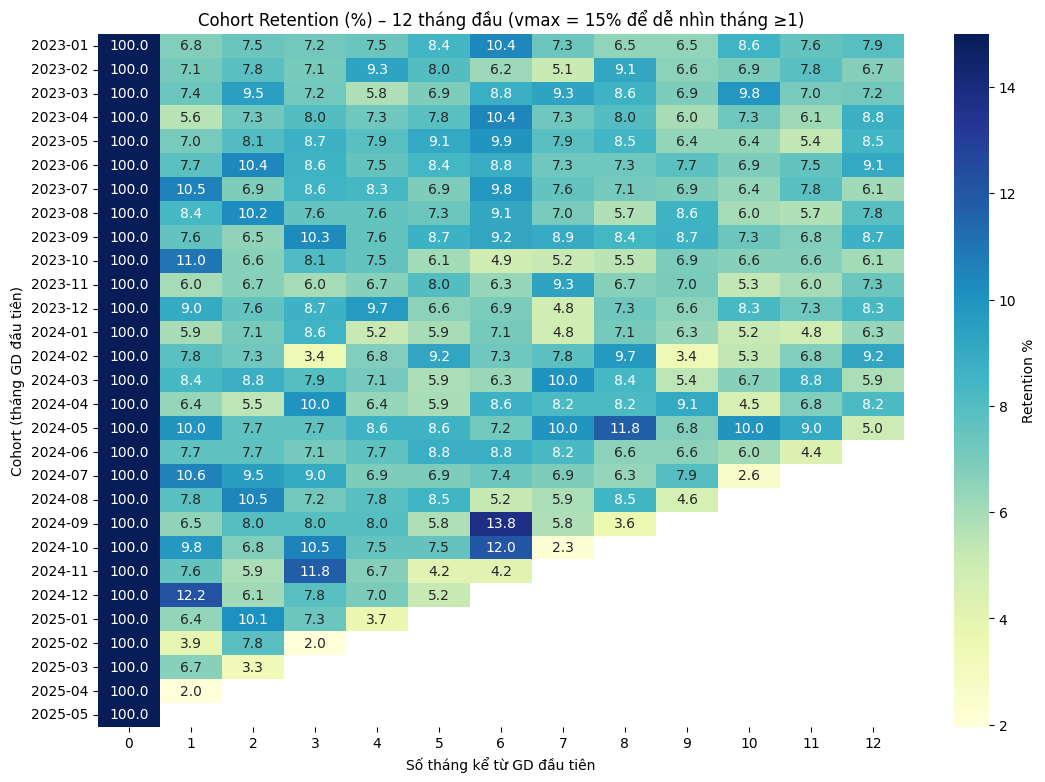

In [ ]:
# ---------- Cohort: tháng giao dịch đầu tiên của khách ----------
first_month = df.groupby('CustomerID').YearMonth.min()
act = df[['CustomerID', 'YearMonth']].drop_duplicates()
act['Cohort'] = act.CustomerID.map(first_month)
act['Index']  = (act.YearMonth - act.Cohort).map(lambda x: x.n)

cohort_cnt = act.pivot_table(index='Cohort', columns='Index', values='CustomerID', aggfunc='nunique')
cohort_ret = cohort_cnt.div(cohort_cnt[0], axis=0) * 100

plt.figure(figsize=(13, 9))
sns.heatmap(cohort_ret.iloc[:, :13], annot=True, fmt='.1f', cmap='YlGnBu', vmax=15, cbar_kws={'label': 'Retention %'})
plt.title('Cohort Retention (%) – 12 tháng đầu (vmax = 15% để dễ nhìn tháng ≥1)'); plt.ylabel('Cohort (tháng GD đầu tiên)'); plt.xlabel('Số tháng kể từ GD đầu tiên')
plt.show()

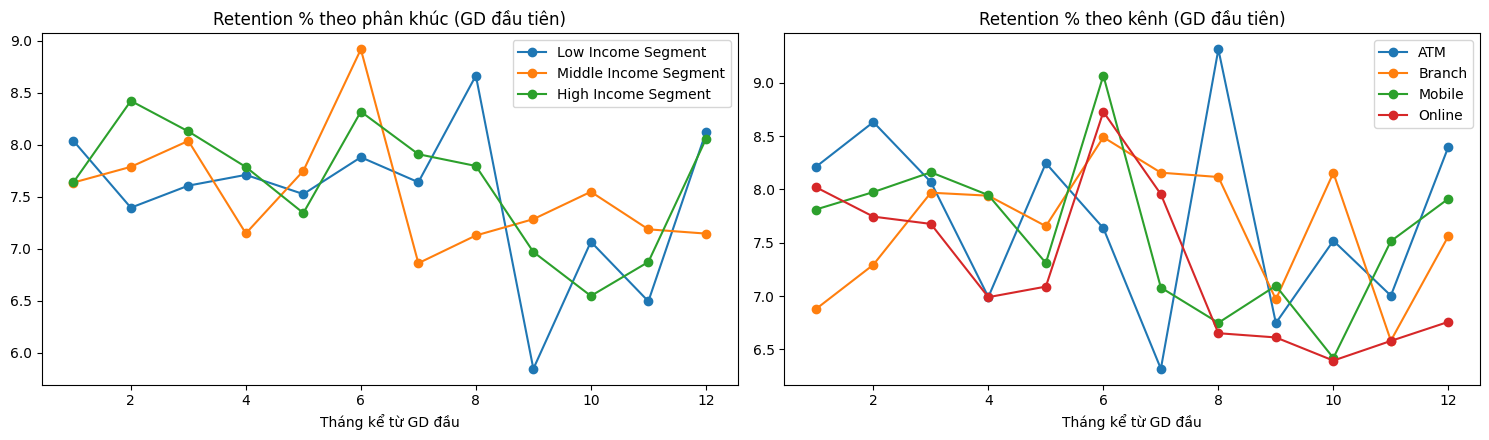

Retention gộp trung bình (tháng 1, 3, 6, 12):


,1,3,6,12
Retention_%,7.73,7.97,8.49,7.66


In [ ]:
# Đường retention gộp (chỉ tính các cohort đã đủ "tuổi" quan sát) + theo phân khúc của giao dịch đầu tiên
def pooled_retention(sub, max_idx=12):
    sizes = sub.groupby('Cohort').CustomerID.nunique()
    a = sub.groupby(['Cohort', 'Index']).CustomerID.nunique().unstack(fill_value=0).reindex(columns=range(max_idx + 1), fill_value=0)
    out = {}
    for k in range(max_idx + 1):
        ok = [c for c in sizes.index if c + k <= LAST_FULL_MONTH]
        if ok: out[k] = a.loc[ok, k].sum() / sizes.loc[ok].sum() * 100
    return pd.Series(out)

first_seg = df.sort_values('TransactionDate').groupby('CustomerID').CustomerSegment.first()
first_ch  = df.sort_values('TransactionDate').groupby('CustomerID').Channel.first()
act['FirstSegment'] = act.CustomerID.map(first_seg); act['FirstChannel'] = act.CustomerID.map(first_ch)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
curves_seg = pd.DataFrame({s: pooled_retention(act[act.FirstSegment == s]) for s in SEGMENT_ORDER})
curves_ch  = pd.DataFrame({c: pooled_retention(act[act.FirstChannel == c]) for c in sorted(df.Channel.unique())})
curves_seg.iloc[1:].plot(marker='o', ax=ax[0]); ax[0].set_title('Retention % theo phân khúc (GD đầu tiên)'); ax[0].set_xlabel('Tháng kể từ GD đầu')
curves_ch.iloc[1:].plot(marker='o', ax=ax[1]);  ax[1].set_title('Retention % theo kênh (GD đầu tiên)');       ax[1].set_xlabel('Tháng kể từ GD đầu')
plt.tight_layout(); plt.show()
print('Retention gộp trung bình (tháng 1, 3, 6, 12):'); display(pooled_retention(act).loc[[1, 3, 6, 12]].round(2).to_frame('Retention_%').T)

===== Xu hướng tỷ trọng theo KÊNH =====


,Share_dau_ky_%,Share_cuoi_ky_%,Slope_pp_moi_nam,p_value,Xu_huong
Channel,,,,,
ATM,24.153596,24.205845,0.063137,0.879393,Không xác định
Branch,26.078719,26.311100,-0.128980,0.805897,Không xác định
Mobile,26.485430,25.425604,0.013852,0.973217,Không xác định
Online,23.282255,24.057451,0.051992,0.908187,Không xác định


===== Xu hướng tỷ trọng theo PHÂN KHÚC =====


,Share_dau_ky_%,Share_cuoi_ky_%,Slope_pp_moi_nam,p_value,Xu_huong
CustomerSegment,,,,,
High Income Segment,33.336476,34.027639,0.140949,0.785676,Không xác định
Low Income Segment,22.505480,22.047221,-0.089336,0.851324,Không xác định
Middle Income Segment,44.158044,43.925139,-0.051612,0.912958,Không xác định


===== Xu hướng tỷ trọng theo NHÓM SẢN PHẨM =====


,Share_dau_ky_%,Share_cuoi_ky_%,Slope_pp_moi_nam,p_value,Xu_huong
ProductCategory,,,,,
Checking Account,18.431704,18.975517,0.485997,0.300047,Không xác định
Credit Card,20.764368,19.874430,-0.471655,0.173644,Không xác định
Loan,19.527441,20.965781,0.432863,0.261152,Không xác định
Mortgage,20.830341,20.534201,0.117190,0.777719,Không xác định
Savings Account,20.446147,19.650071,-0.564395,0.127825,Không xác định


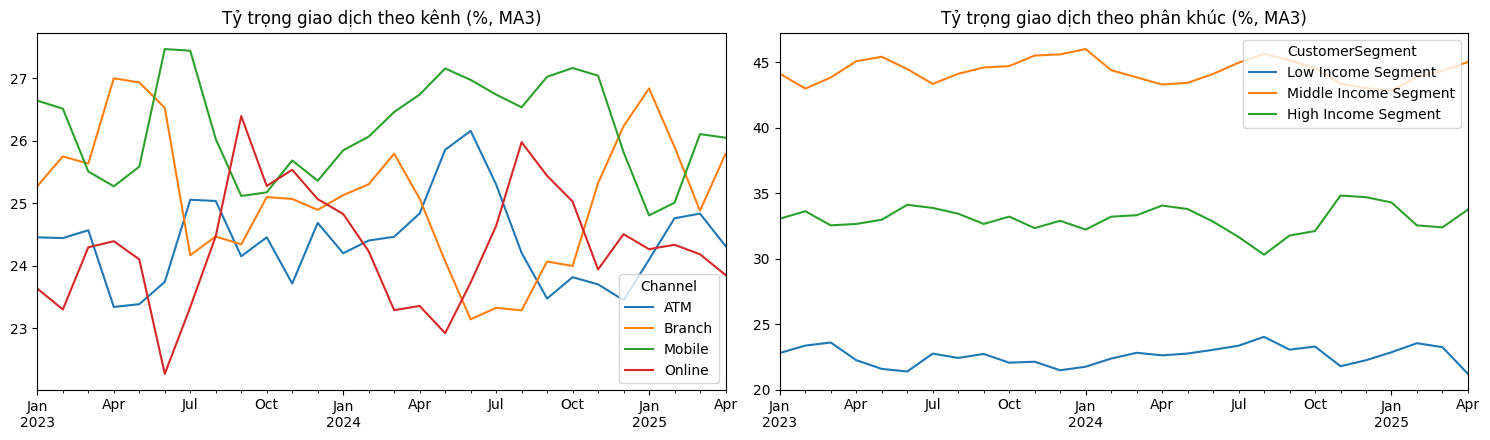

In [ ]:
# ---------- Xu hướng tỷ trọng theo thời gian ----------
def share_trend(col):
    sh = pd.crosstab(full.YearMonth, full[col], normalize='index') * 100
    rows = []
    x = np.arange(len(sh))
    for c in sh.columns:
        r = stats.linregress(x, sh[c].values)
        rows.append({col: c, 'Share_dau_ky_%': sh[c].iloc[:6].mean(), 'Share_cuoi_ky_%': sh[c].iloc[-6:].mean(),
                     'Slope_pp_moi_nam': r.slope * 12, 'p_value': r.pvalue,
                     'Xu_huong': ('Tăng' if r.slope > 0 else 'Giảm') if r.pvalue < 0.05 else 'Không xác định'})
    return sh, pd.DataFrame(rows).set_index(col)

sh_ch, tr_ch   = share_trend('Channel')
sh_seg, tr_seg = share_trend('CustomerSegment')
sh_cat, tr_cat = share_trend('ProductCategory')
for n, t in [('KÊNH', tr_ch), ('PHÂN KHÚC', tr_seg), ('NHÓM SẢN PHẨM', tr_cat)]:
    print(f'===== Xu hướng tỷ trọng theo {n} ====='); display(t)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sh_ch.rolling(3, min_periods=1).mean().plot(ax=ax[0]); ax[0].set_title('Tỷ trọng giao dịch theo kênh (%, MA3)'); ax[0].set_xlabel('')
sh_seg[SEGMENT_ORDER].rolling(3, min_periods=1).mean().plot(ax=ax[1]); ax[1].set_title('Tỷ trọng giao dịch theo phân khúc (%, MA3)'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

In [ ]:
# ---------- So sánh cùng kỳ: Jan–Apr 2024 vs Jan–Apr 2025 ----------
ytd = df[(df.Month <= 4) & (df.Year.isin([2024, 2025]))]
def yoy(col, val='TransactionID', agg='count'):
    t = ytd.pivot_table(index=col, columns='Year', values=val, aggfunc=agg)
    t['YoY_%'] = (t[2025] / t[2024] - 1) * 100
    return t
print('Số giao dịch – YoY (Jan–Apr):')
display(pd.concat({'Kênh': yoy('Channel'), 'Phân khúc': yoy('CustomerSegment'), 'Nhóm SP': yoy('ProductCategory')}))
print('Doanh thu phí – YoY (Jan–Apr):')
display(pd.concat({'Kênh': yoy('Channel', 'TotalFees', 'sum'), 'Phân khúc': yoy('CustomerSegment', 'TotalFees', 'sum')}))
tot = ytd.groupby('Year').agg(GD=('TransactionID', 'count'), GiaTri=('Amount', 'sum'), Phi=('TotalFees', 'sum'))
display(tot.T.assign(**{'YoY_%': lambda d: (d[2025] / d[2024] - 1) * 100}))

Số giao dịch – YoY (Jan–Apr):


Year                             2024  2025      YoY_%
Kênh      ATM                     678   702   3.539823
          Branch                  688   730   6.104651
          Mobile                  740   734  -0.810811
          Online                  638   680   6.583072
Phân khúc High Income Segment     922   941   2.060738
          Low Income Segment      614   627   2.117264
          Middle Income Segment  1208  1278   5.794702
Nhóm SP   Checking Account        534   544   1.872659
          Credit Card             571   572   0.175131
          Loan                    543   578   6.445672
          Mortgage                536   601  12.126866
          Savings Account         560   551  -1.607143

Doanh thu phí – YoY (Jan–Apr):


Year                                 2024      2025      YoY_%
Kênh      ATM                    21549.34  20671.13  -4.075345
          Branch                 21074.05  23802.04  12.944783
          Mobile                 22230.97  24982.47  12.376878
          Online                 20641.90  19550.25  -5.288515
Phân khúc High Income Segment    28943.33  30126.73   4.088679
          Low Income Segment     18108.79  20605.83  13.789105
          Middle Income Segment  38444.14  38273.33  -0.444307

Year,2024,2025,YoY_%
GD,2.744000e+03,2.846000e+03,3.717201
GiaTri,1.360865e+07,1.436947e+07,5.590647
Phi,8.549626e+04,8.900589e+04,4.105010



> ### 💡 Nhận xét 4.3
> - **Cohort:** retention gộp chỉ ~**7,7% sau 1 tháng**, ~8,0% sau 3 tháng, ~8,5% sau 6 tháng, ~7,7% sau 12 tháng – tức **gần như phẳng**: mỗi tháng chỉ ~8% khách quay lại, và xác suất quay lại *không tăng* theo thời gian (không có hiệu ứng "gắn kết dần"). Đây là điểm yếu giữ chân chính của bộ dữ liệu (và khớp với việc 27% khách chỉ giao dịch 1 lần).
> - **Xu hướng tỷ trọng theo tháng (hồi quy tuyến tính):** không có kênh, phân khúc hay nhóm sản phẩm nào có xu hướng tăng/giảm có ý nghĩa thống kê (mọi p > 0,13; độ dốc < 0,6 điểm %/năm).
> - **Cùng kỳ Jan–Apr 2025 vs 2024:** giao dịch **+3,7%**, giá trị **+5,6%**, doanh thu phí **+4,1%**. Nổi lên: *Mortgage +12,1%*, *Loan +6,5%*, *Online +6,6%*, *Branch +6,1%*; *Mobile −0,8%*, *Savings −1,6%*. Về doanh thu phí: *Low Income +13,8%*, *Branch +12,9%*, *Mobile +12,4%* trong khi *ATM −4,1%*, *Online −5,3%*.
> - ⚠️ Mỗi ô chỉ ~600–1.300 giao dịch nên chênh lệch ±5% nằm gần ngưỡng nhiễu; đây là **tín hiệu cần theo dõi** (đặc biệt Mortgage, phí của nhóm Low Income) chứ chưa phải xu hướng đã được khẳng định.



# 4️⃣ CONCLUSION & KHUYẾN NGHỊ

## 4.1 Trả lời nhanh các câu hỏi của thử thách
| # | Câu hỏi | Trả lời ngắn gọn | Phương pháp |
|---|---|---|---|
| 1.1 | Phân khúc năng nổ nhất | **Middle Income** (44% GD, ~1,56 GD/khách); Champions (20% khách) tạo ~35% giá trị | Mô tả + RFM |
| 1.2 | Sản phẩm phổ biến theo phân khúc | Cơ cấu **đồng đều ~20%**, không khác biệt ý nghĩa (χ² p = 0,20) | Crosstab + Sankey |
| 1.3 | Điểm tín dụng vs tần suất/phí | **Không** có tương quan (ρ ≈ 0) | Spearman |
| 2.1 | Loại giao dịch chiếm ưu thế | **Không có** – 6 loại chia đều ~16,5–17%; không có 80/20 | Pareto |
| 2.2 | Điểm nóng / kém hiệu quả | Nóng: **Barcelona, Malaga, Murcia**; kém: **Madrid, Bilbao** (hạng B); điểm phục vụ hạng C: Seville\|Online, Barcelona\|ATM, Madrid\|Online | ABC + Pareto |
| 2.3 | Khác biệt giữa các kênh | **Không có khác biệt ý nghĩa**; Mobile dẫn đầu số lượng, ATM có giá trị TB cao nhất | Mô tả + χ² + Sankey |
| 3.1 | Loại GD sinh nhiều phí nhất | **Loan Payment ~60%** doanh thu phí; phí phạt (LatePayment) 52% | Pareto |
| 3.2 | Nhóm chịu chi phí không tương xứng | **Low Income** (phí/thu nhập 1,68% vs 0,38% của High), sản phẩm **Loan** & **Credit Card** | Burden Index + RFM |
| 3.3 | Ma sát nhưng sinh doanh thu | Khoản phí trên **Loan Payment** (~98,9/lần, 100% giao dịch Loan Payment) | Funnel + tần suất–doanh thu |
| 4.1 | Mùa vụ | **Không có** mùa vụ đáng kể (chỉ số 96–102; p = 0,77) | Chuỗi thời gian |
| 4.2 | Offer có phù hợp hành vi? | **Một phần** – khớp thu nhập/sản phẩm, nhưng không dựa trên hành vi và không nhất quán theo khách | MBA + Sankey + Funnel |
| 4.3 | Xu hướng mới nổi | Retention phẳng ~8%/tháng; tín hiệu cần theo dõi: Mortgage, Online/Branch, phí Low Income | Cohort + YoY |

## 4.2 Ba thông điệp quan trọng nhất
1. **Dữ liệu rất "đồng đều":** phần lớn các chiều (kênh, thành phố, loại giao dịch, mùa vụ, điểm tín dụng) *không* tạo khác biệt ý nghĩa thống kê. Vì vậy các khác biệt nhỏ nên được diễn giải thận trọng.
2. **Điểm tạo khác biệt thật sự nằm ở cấu trúc phí:** doanh thu phí tập trung vào Loan Payment (60%) và tạo gánh nặng lũy thoái lên nhóm thu nhập thấp.
3. **Cá nhân hoá còn yếu:** offer gán theo quy tắc (Phân khúc × Sản phẩm), thay đổi theo từng giao dịch, không dùng tín hiệu hành vi; retention chỉ ~8%/tháng.

## 4.3 Khuyến nghị hành động
| Ưu tiên | Khuyến nghị | Căn cứ |
|---|---|---|
| 🔴 Cao | **Win-back nhóm At Risk** (~980 khách, ~18% giá trị) bằng ưu đãi cá nhân hoá | RFM |
| 🔴 Cao | **Rà soát cơ chế phí trên Loan Payment** (đa dạng hoá nguồn thu, giảm rủi ro uy tín/pháp lý); cân nhắc trần phí cho nhóm Low Income | Pareto, Burden Index |
| 🟠 Trung bình | **Xây lại logic offer** theo hành vi (recency, tần suất, phí đã chịu, sản phẩm đang thiếu) và cố định offer theo *khách* thay vì theo *giao dịch* | Phân tích offer, MBA |
| 🟠 Trung bình | **Chương trình kéo khách quay lại** sau giao dịch đầu (27% chỉ giao dịch 1 lần; retention ~8%) và chiến dịch bán chéo cho 2.738 khách chỉ dùng 1 nhóm sản phẩm | Cohort, Funnel Product Holdings |
| 🟡 Theo dõi | Rà soát điểm phục vụ hạng C (Seville\|Online, Barcelona\|ATM, Madrid\|Online); theo dõi Mortgage, kênh Online/Branch | ABC, YoY |

## 4.4 Hạn chế của phân tích
- `CustomerSegment`, `MonthlyIncome`, `CustomerScore` thay đổi giữa các giao dịch của cùng một khách → coi là thuộc tính *tại thời điểm giao dịch*.
- Dataset không có `BranchID` (chỉ có thành phố), không có trạng thái giao dịch (nên Funnel được điều chỉnh sang funnel phí/product holdings) và có 2 loại tiền tệ chưa quy đổi (bật `NORMALIZE_CURRENCY` nếu có tỷ giá).
- Bảng ánh xạ `OFFER_TARGET` là **giả định của người phân tích** – có thể chỉnh sửa để phù hợp nghiệp vụ.
- Phần lớn khác biệt nhỏ chưa vượt ngưỡng ý nghĩa thống kê; các số YoY dựa trên mẫu nhỏ.

## 4.5 Hướng mở rộng
- Mô hình dự báo churn/khả năng quay lại (Logistic Regression, Gradient Boosting) từ các biến RFM + phí.
- Mô phỏng tác động nếu áp trần phí Loan Payment lên doanh thu và retention.
- A/B test offer theo hành vi so với offer theo quy tắc hiện tại.
